# 51. Topology-aware correction-to-go FM: 90° / 179° stochastic ablations and physical-window rollouts

Initialize **FM51 from the trained FM50 angular-curriculum checkpoint**, with unchanged architecture, on-policy correction-to-go supervision, and differentiable endpoint loss.

1. Run a **reversible stochastic experiment** on a topology mixture, choosing a separate `STOCHASTIC_COARSE_MAX_DEG` (90 or 179). Optionally save only its candidate model weights for comparison.
2. Optionally run full topology-mixture training using independent loss weights and a fixed coarse maximum; resume only from FM51's own last checkpoint.
3. Compare FM51 (or its stochastic candidate) against **the exact FM50 source checkpoint** on controlled per-topology angular bins and chronological **multi-window** calibration rollouts averaged across start positions and random rotation axes.

**Physical rollout convention:** Each model starts with the same corrupted calibration and receives consecutive, held-out *validation* windows. Its own updated calibration is fed into the next window, with no truth reset. All keys may be updated (default) or the corrupted key only for an isolation check. A fixed sensor rig is required throughout a rollout; synthetic topology continuity is verified explicitly before use.

**Scope:** This notebook tests FM as a coarse calibrator. Regression refinement is deliberately left for a subsequent experiment; it is not used to initialize the FM flow.

## 1. Imports and project root

In [1]:
from pathlib import Path
from dataclasses import asdict, fields, is_dataclass, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the nn-obs-calib repository root (must contain src/obscalib).")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationFlowIntegratorConfig, CalibrationFlowLossConfig, CalibrationPoolerConfig, MLPConfig, PooledCalibrationFlowConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch, TokenBatch
from obscalib.flow_matching.loss import calibration_velocity_loss
from obscalib.flow_matching.calibration_path import make_correction_to_go_flow_batch
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print("ROOT", ROOT, "| PyTorch", torch.__version__, "| CUDA", torch.cuda.is_available())


ROOT /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch 2.7.1+cu126 | CUDA True


## 2. Independent experiment settings

In [33]:
RUN_NAME = "kaist_pooled_calibration_fm.8_topology_179"
SOURCE_FM_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.7_angle_curriculum" / "best.pt"
# Alternative: ... / "best_stage_179deg.pt" or ... / "last.pt"
RUN_DIR = ROOT / "runs" / RUN_NAME
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"

SEED = 12345
TRAIN_AUG_SEED, VAL_AUG_SEED, TEST_AUG_SEED = 23456, 34567, 45678
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
MEASUREMENT_DIM = 6
WINDOW_DURATION_S, WINDOW_STRIDE_S = 5.0, 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE, NUM_WORKERS = 4, 0

HEAD_LEARNING_RATE, BACKBONE_LEARNING_RATE = 3e-5, 3e-6
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
GRADIENT_ACCUMULATION_STEPS = 4
FLOW_PATH_NUM_POINTS = 9
TRAIN_INTEGRATION_STEPS = 4
TRAIN_INTEGRATION_METHOD = "euler"
VELOCITY_LOSS_WEIGHT, ENDPOINT_LOSS_WEIGHT = 1.0, 0.2
FM_INTEGRATION_STEPS, FM_INTEGRATION_METHOD = 16, "midpoint"
ABLATION_STEPS = (1, 2, 4, 8, 16, 32)

# FULL TRAINING ONLY: these do not control stochastic preflight.
RUN_FULL_TRAINING = True
RESUME_FULL_TRAINING = True       # FM51 last.pt only; fresh run loads FM50 source
FULL_INIT_FROM_STOCHASTIC_CANDIDATE = False   # Optional warm start after successful stochastic diagnostic
FULL_STOCHASTIC_INIT_ANGLE_DEG = 179.0
TRAIN_EPOCHS = 200
FULL_TRAIN_TOPOLOGY = "mixture"
FULL_TRAIN_REGIME = "mixed"
FULL_COARSE_MAX_DEG = 179.0
FULL_FINE_LOSS_WEIGHT = 0.50
FULL_COARSE_LOSS_WEIGHT = 0.50
MAX_TRAIN_BATCHES_PER_EPOCH = None
MAX_VAL_BATCHES_PER_EPOCH = None
REGIME_VALIDATION_BATCHES = 3
LR_REDUCE_STEPS, LR_REDUCE_FACTOR = 8, 0.5
RUN_TOPOLOGY_DIAGNOSTICS_EVERY = 5
REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING = False

FULL_STATE_MODE = "mixed"
FULL_OFF_PATH_PROBABILITY, FULL_IDENTITY_PROBABILITY = 0.50, 0.15
FULL_MAX_FLOW_TIME = 0.975
FULL_OFF_PATH_ROTATION_STD_DEG = 8.0
FULL_OFF_PATH_TRANSLATION_STD_M, FULL_OFF_PATH_TAU_STD_S = 0.02, 0.02
FULL_RANDOMIZED_INTEGRATION, FULL_RANDOMIZE_QUERY_TIMES = True, True
FULL_OBJECTIVE = dict(
    mode=FULL_STATE_MODE, off_path_probability=FULL_OFF_PATH_PROBABILITY,
    identity_probability=FULL_IDENTITY_PROBABILITY, max_time=FULL_MAX_FLOW_TIME,
    rotation_noise_std_rad=np.deg2rad(FULL_OFF_PATH_ROTATION_STD_DEG),
    translation_noise_std_m=FULL_OFF_PATH_TRANSLATION_STD_M,
    tau_noise_std_s=FULL_OFF_PATH_TAU_STD_S,
    velocity_weight=VELOCITY_LOSS_WEIGHT, endpoint_weight=ENDPOINT_LOSS_WEIGHT,
    randomized_integration=FULL_RANDOMIZED_INTEGRATION,
    randomized_query_times=FULL_RANDOMIZE_QUERY_TIMES,
    on_policy_fraction=0.50, on_policy_steps=8, on_policy_max_time=0.875,
    on_policy_method="midpoint",
)

# Stochastic ONLY: edit these for rapid 90° / 179° comparisons.
RUN_STOCHASTIC_CHECK = True
STOCHASTIC_CHECK_PASSED = None
precheck_history, precheck_final = [], None
STOCHASTIC_COARSE_MAX_DEG = 179.0     # Set 90.0 or 179.0; completely independent of FULL_COARSE_MAX_DEG
STOCHASTIC_TRAIN_TOPOLOGY = "mixture"
STOCHASTIC_TRAIN_REGIME = "mixed"
STOCHASTIC_FINE_LOSS_WEIGHT = 0.50
STOCHASTIC_COARSE_LOSS_WEIGHT = 0.50
STOCHASTIC_WINDOWS = min(BATCH_SIZE, 6)
STOCHASTIC_STEPS, STOCHASTIC_REPORT_EVERY = 200, 10
STOCHASTIC_HEAD_LR, STOCHASTIC_BACKBONE_LR = 1e-4, 1e-5
STOCHASTIC_SAVE_CANDIDATE = True     # Save best diagnostic candidate; original model/optimizer restored
STOCHASTIC_INITIALIZATION_CHECKPOINT = SOURCE_FM_CHECKPOINT  # Always same FM50 source for 90° vs 179°
STOCHASTIC_SEED, STOCHASTIC_EVAL_SEED = TRAIN_AUG_SEED + 200000, VAL_AUG_SEED + 300000
STOCHASTIC_STATE_MODE = "mixed"
STOCHASTIC_OFF_PATH_PROBABILITY, STOCHASTIC_IDENTITY_PROBABILITY = 0.60, 0.20
STOCHASTIC_MAX_FLOW_TIME = 0.975
STOCHASTIC_ROTATION_NOISE_STD_DEG = 10.0
STOCHASTIC_TRANSLATION_NOISE_STD_M, STOCHASTIC_TAU_NOISE_STD_S = 0.02, 0.02
STOCHASTIC_VELOCITY_LOSS_WEIGHT, STOCHASTIC_ENDPOINT_LOSS_WEIGHT = 1.0, 0.2
STOCHASTIC_RANDOMIZED_INTEGRATION, STOCHASTIC_RANDOMIZE_QUERY_TIMES = True, True
STOCHASTIC_GRAD_CLIP_NORM = 1.0
STOCHASTIC_OBJECTIVE = dict(
    mode=STOCHASTIC_STATE_MODE, off_path_probability=STOCHASTIC_OFF_PATH_PROBABILITY,
    identity_probability=STOCHASTIC_IDENTITY_PROBABILITY, max_time=STOCHASTIC_MAX_FLOW_TIME,
    rotation_noise_std_rad=np.deg2rad(STOCHASTIC_ROTATION_NOISE_STD_DEG),
    translation_noise_std_m=STOCHASTIC_TRANSLATION_NOISE_STD_M,
    tau_noise_std_s=STOCHASTIC_TAU_NOISE_STD_S,
    velocity_weight=STOCHASTIC_VELOCITY_LOSS_WEIGHT,
    endpoint_weight=STOCHASTIC_ENDPOINT_LOSS_WEIGHT,
    randomized_integration=STOCHASTIC_RANDOMIZED_INTEGRATION,
    randomized_query_times=STOCHASTIC_RANDOMIZE_QUERY_TIMES,
    on_policy_fraction=0.50, on_policy_steps=8, on_policy_max_time=0.875,
    on_policy_method="midpoint",
)

# Shared physical data and augmentation definitions.
FINE_PRIOR_PROBABILITY = 0.50
FINE_ROTATION_MAX_RAD, FINE_ROTATION_SCALE_RAD = np.deg2rad(60.0), np.deg2rad(30.0)
FINE_TIME_OFFSET_MAX_S, FINE_TIME_OFFSET_SCALE_S = 0.500, 0.250
COARSE_ROTATION_MAX_RAD = np.deg2rad(FULL_COARSE_MAX_DEG)
COARSE_TIME_OFFSET_MAX_S, COARSE_TIME_OFFSET_SCALE_S = 0.500, 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
TRUE_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_TIME_OFFSET_MAX_S = 0.030
TOPOLOGY_MODES = ("original", "replace_lidar", "replace_lidar_right")
TOPOLOGY_PROBABILITIES = (0.50, 0.25, 0.25)
TOPOLOGY_SYNTHETIC_MOUNT_MAX_DEG = 180.0
TOPOLOGY_SYNTH_GYRO_NOISE_STD = 0.0
TOPOLOGY_SYNTH_ACCEL_NOISE_STD = 0.0
EXPECTED_KEYS_BY_TOPOLOGY = {
    "original": frozenset(("imu", "lidar", "lidar_right")),
    "replace_lidar": frozenset(("imu", "imu_synth", "lidar_right")),
    "replace_lidar_right": frozenset(("imu", "lidar", "imu_synth")),
}
assert np.isclose(sum(TOPOLOGY_PROBABILITIES), 1.0)
assert FINE_ROTATION_MAX_RAD <= COARSE_ROTATION_MAX_RAD < np.pi
for value in (STOCHASTIC_COARSE_MAX_DEG, FULL_COARSE_MAX_DEG):
    assert 60.0 <= value < 180.0
for pair in ((STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT),
             (FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT)):
    assert all(weight >= 0 for weight in pair) and sum(pair) > 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
if not SOURCE_FM_CHECKPOINT.is_file():
    raise FileNotFoundError(SOURCE_FM_CHECKPOINT)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Source FM50 checkpoint:", SOURCE_FM_CHECKPOINT)
print("Stochastic:", STOCHASTIC_COARSE_MAX_DEG, STOCHASTIC_TRAIN_TOPOLOGY, STOCHASTIC_TRAIN_REGIME,
      "loss weights", (STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT))
print("Full training:", FULL_COARSE_MAX_DEG, FULL_TRAIN_TOPOLOGY, FULL_TRAIN_REGIME,
      "loss weights", (FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT), "enabled", RUN_FULL_TRAINING)

Source FM50 checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.7_angle_curriculum/best.pt
Stochastic: 179.0 mixture mixed loss weights (0.5, 0.5)
Full training: 179.0 mixture mixed loss weights (0.5, 0.5) enabled True


## 3. KAIST datasets and physical augmentation (unchanged)

In [17]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
assert len(set(ALL_SEQUENCE_NAMES)) == len(ALL_SEQUENCE_NAMES)

T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_right = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=float)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV required by 002.24 architecture: {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config, measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64, window_timestamp_dtype=DTYPE)

train_dataset, val_dataset, test_dataset = (make_dataset(names) for names in (TRAIN_NAMES, VAL_NAMES, TEST_NAMES))
for name, ds in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(ds.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"Unexpected calibration keys for {name}: {ds.calibration_keys}")
    print(name, len(ds), "windows")

train_shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

train 2006 windows
validation 418 windows
test 699 windows


In [18]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

def topology_config_for_mode(mode: str) -> SensorTopologyAugmentationConfig:
    if mode not in TOPOLOGY_MODES:
        raise ValueError(mode)
    return SensorTopologyAugmentationConfig(
        enabled=(mode != "original"), replacement_probability=1.0,
        replace_first_lidar_probability=1.0 if mode == "replace_lidar" else 0.0,
        maximum_mount_rotation_deg=TOPOLOGY_SYNTHETIC_MOUNT_MAX_DEG,
        synthetic_gyro_noise_std=TOPOLOGY_SYNTH_GYRO_NOISE_STD,
        synthetic_accel_noise_std=TOPOLOGY_SYNTH_ACCEL_NOISE_STD,
    )

physical_augmenters = {
    mode: AugmentationPipeline(replace(true_calibration_config, sensor_topology=topology_config_for_mode(mode)))
    for mode in TOPOLOGY_MODES
}

fine_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=FINE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=FINE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
coarse_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=COARSE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=COARSE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.UNIFORM, scale=COARSE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

def augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def clone_with_current_calibration(window: WindowBatch, new_calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=new_calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)

# Probability that each calibration receives the ONE prior fault in a physical window.
# Keep original KAIST unchanged; emphasize the remaining real LiDAR in 2-IMU/1-LiDAR cases.
FAULT_KEY_WEIGHTS = {
    frozenset(("imu", "lidar", "lidar_right")): {"imu": 1.0, "lidar": 1.0, "lidar_right": 1.0},
    frozenset(("imu", "imu_synth", "lidar_right")): {"imu": 0.20, "imu_synth": 0.20, "lidar_right": 0.60},
    frozenset(("imu", "lidar", "imu_synth")): {"imu": 0.20, "lidar": 0.60, "imu_synth": 0.20},
}

def sample_fine_coarse_deltas(true_states, generator: torch.Generator, regime: str = "mixed"):
    if regime not in {"mixed", "fine", "coarse"}:
        raise ValueError(regime)

    keys = tuple(true_states)
    probability_by_key = FAULT_KEY_WEIGHTS.get(frozenset(keys))
    if probability_by_key is None:
        raise ValueError(f"No fault-selection weights for calibration keys {keys}")

    template = next(iter(true_states.values())).transform
    n = len(template)
    weights = torch.tensor([probability_by_key[key] for key in keys], device=template.device, dtype=torch.float32)
    weights = weights / weights.sum()
    selected_key_indices = torch.multinomial(weights, n, replacement=True, generator=generator)

    if regime == "mixed":
        fine_mask = torch.rand(n, device=template.device, generator=generator) < FINE_PRIOR_PROBABILITY
    else:
        fine_mask = torch.full((n,), regime == "fine", device=template.device, dtype=torch.bool)

    # Reuse the existing perturbers on single-key dictionaries. This preserves their
    # exact Student-t/uniform SO(3) and tau distributions while controlling key choice.
    xi, tau = {}, {}
    for key_index, key in enumerate(keys):
        singleton = {key: true_states[key]}
        if regime != "coarse":
            _, fine_xi, fine_tau = fine_prior_perturber(singleton, generator=generator)
        if regime != "fine":
            _, coarse_xi, coarse_tau = coarse_prior_perturber(singleton, generator=generator)

        if regime == "fine":
            chosen_xi, chosen_tau = fine_xi[key], fine_tau[key]
        elif regime == "coarse":
            chosen_xi, chosen_tau = coarse_xi[key], coarse_tau[key]
        else:
            chosen_xi = torch.where(fine_mask[:, None], fine_xi[key], coarse_xi[key])
            chosen_tau = torch.where(fine_mask[:, None], fine_tau[key], coarse_tau[key])

        selected = (selected_key_indices == key_index)[:, None]
        xi[key] = torch.where(selected, chosen_xi, torch.zeros_like(chosen_xi))
        tau[key] = torch.where(selected, chosen_tau, torch.zeros_like(chosen_tau))

    return xi, tau, fine_mask

@torch.no_grad()
def augment_topology_window(base_window: WindowBatch, generator: torch.Generator, *, topology: str, regime: str = "mixed") -> WindowBatch:
    if topology not in TOPOLOGY_MODES:
        raise ValueError(topology)
    physical = physical_augmenters[topology](base_window, generator=generator).augmented_window
    truth_states = physical.current_calibration
    assert frozenset(truth_states) == EXPECTED_KEYS_BY_TOPOLOGY[topology], (topology, tuple(truth_states))
    xi, tau, _ = sample_fine_coarse_deltas(truth_states, generator, regime=regime)
    return clone_with_current_calibration(physical, apply_prior_perturbation(truth_states, xi, tau))

def correction_targets(window: WindowBatch):
    if window.targets is None:
        raise ValueError("Expected truth targets after topology/true-calibration augmentation")
    targets_xi, targets_tau = {}, {}
    for key, state in window.current_calibration.items():
        target = window.targets[key]
        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Missing correction truth for {key}")
        targets_xi[key] = se3_log(target.next_transform @ torch.linalg.inv(state.transform))
        targets_tau[key] = target.next_time_offset - state.time_offset
    return targets_xi, targets_tau

print("Physical pipeline:", {name: p.config.sensor_topology for name, p in physical_augmenters.items()})
print("Unchanged fine/coarse priors:", fine_prior_config, coarse_prior_config)

Physical pipeline: {'original': SensorTopologyAugmentationConfig(enabled=False, replacement_probability=1.0, replace_first_lidar_probability=0.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_right'), synthetic_calibration_key='imu_synth', synthetic_gyro_stream='gyro_synth', synthetic_accel_stream='accel_synth', maximum_mount_rotation_deg=180.0, synthetic_gyro_noise_std=0.0, synthetic_accel_noise_std=0.0), 'replace_lidar': SensorTopologyAugmentationConfig(enabled=True, replacement_probability=1.0, replace_first_lidar_probability=1.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_right'), synthetic_calibration_key='imu_synth', synthetic_gyro_stream='gyro_synth', synthetic_accel_stream='accel_synth', maximum_mount_rotation_deg=180.0, synthetic_gyro_noise_std=0.0, synthetic_accel_noise_std=0.0), 'replace_lidar_right': SensorTopologyAugmentationConfig(enabled=True, replacement_probability=1.0, replace_first_lidar_probability=0.0, source_imu_key='imu', lidar_keys=('lidar', 'lidar_ri

In [19]:
def topology_slice_batch(window: WindowBatch, positions: torch.Tensor) -> WindowBatch:
    n = len(next(iter(window.current_calibration.values())).transform)
    if positions.numel() == 0:
        raise ValueError("Cannot create an empty topology group")
    positions_cpu = positions.detach().cpu().tolist()
    original_indices = window.dataset_indices
    if isinstance(original_indices, torch.Tensor):
        selected_indices = original_indices.index_select(0, positions.to(device=original_indices.device))
    elif original_indices is not None and hasattr(original_indices, "__len__") and len(original_indices) == n:
        selected = [original_indices[i] for i in positions_cpu]
        selected_indices = tuple(selected) if isinstance(original_indices, tuple) else selected
    else:
        selected_indices = original_indices

    def select(item):
        if isinstance(item, torch.Tensor) and item.ndim > 0 and item.shape[0] == n:
            return item.index_select(0, positions.to(device=item.device))
        if is_dataclass(item) and not isinstance(item, type):
            updates = {field.name: (selected_indices if isinstance(item, WindowBatch) and field.name == "dataset_indices" else select(getattr(item, field.name))) for field in fields(item) if field.init}
            return replace(item, **updates)
        if isinstance(item, dict):
            return {key: select(value) for key, value in item.items()}
        return item

    return select(window)

def topology_groups(base_window: WindowBatch, generator: torch.Generator, mode: str = "mixture"):
    sample_transform = next(iter(base_window.current_calibration.values())).transform
    n = len(sample_transform)
    if mode == "mixture":
        drawn = torch.rand(n, device=sample_transform.device, generator=generator)
        ids = torch.where(drawn < TOPOLOGY_PROBABILITIES[0], 0, torch.where(drawn < sum(TOPOLOGY_PROBABILITIES[:2]), 1, 2))
    elif mode in TOPOLOGY_MODES:
        ids = torch.full((n,), TOPOLOGY_MODES.index(mode), device=sample_transform.device, dtype=torch.long)
    else:
        raise ValueError(mode)
    return [(name, topology_slice_batch(base_window, positions)) for i, name in enumerate(TOPOLOGY_MODES) if (positions := torch.nonzero(ids == i, as_tuple=False).flatten()).numel()]

# Keep the original input batch intact: topology grouping must be a partition of physical examples.
test_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
groups = topology_groups(test_base, augmentation_generator(TRAIN_AUG_SEED + 18))
assert sum(len(next(iter(w.current_calibration.values())).transform) for _, w in groups) == len(next(iter(test_base.current_calibration.values())).transform)
for mode, group in groups:
    print("Partition", mode, "n=", len(next(iter(group.current_calibration.values())).transform))

Partition original n= 2
Partition replace_lidar_right n= 2


## 4. Load FM50 source model and geometry/loss helpers

In [20]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD, ablation_steps=ABLATION_STEPS),
    loss=CalibrationFlowLossConfig(rotation_scale_rad=np.deg2rad(5.0), translation_scale_m=0.05, time_offset_scale_s=0.05, rotation_weight=2.0, translation_weight=1.0, time_offset_weight=1.0, active_rotation_weight=0.75),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.freeze_feature_extractor(False)
fm_loss_weights = flow_config.loss.to_loss_weights()

for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body, fm_model.head):
    assert all(p.requires_grad for p in module.parameters())
print("FM checkpoint loaded:", SOURCE_FM_CHECKPOINT)
print("FM parameters:", sum(p.numel() for p in fm_model.parameters()), "trainable:", sum(p.numel() for p in fm_model.parameters() if p.requires_grad))

FM checkpoint loaded: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.7_angle_curriculum/best.pt
FM parameters: 2555399 trainable: 2555399


In [21]:
class _CapturedTokens(Exception):
    pass

class _TokenCaptureModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokens = None
        self.context = None

    def forward(self, tokens, calibration_context=None, **kwargs):
        self.tokens = tokens
        self.context = calibration_context
        raise _CapturedTokens()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
capture_model = _TokenCaptureModel()

def tokenize_window(window: WindowBatch):
    # Topology-dependent calibration key set/order MUST be decided after augmentation.
    calibration_keys = tuple(window.current_calibration)
    step = WindowStep(geometry_processor=geometry_processor, tokenizer=Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=calibration_keys), model=capture_model, calibration_updater=calibration_updater)
    capture_model.tokens = None
    capture_model.context = None
    try:
        step(window)
    except _CapturedTokens:
        pass
    if capture_model.tokens is None:
        raise RuntimeError("WindowStep did not call model: failed to capture tokens")
    if tuple(capture_model.tokens.calibration_keys) != calibration_keys:
        raise AssertionError((calibration_keys, capture_model.tokens.calibration_keys))
    return capture_model.tokens, capture_model.context

def flow_supervision(window: WindowBatch, *, generator: torch.Generator, model=None):
    model = fm_model if model is None else model
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
    output = model.forward_flow_matching(tokens, target_xi, target_tau, calibration_context=context, generator=generator)
    loss = calibration_velocity_loss(output.predicted_velocity, output.flow_batch.target_velocity, weights=fm_loss_weights)
    return loss, output

@torch.no_grad()
def model_predictions(model, window, steps=FM_INTEGRATION_STEPS):
    tokens, context = tokenize_window(window)
    if isinstance(model, PooledCalibrationFlowModel):
        return model(tokens, context, num_steps=steps, method=FM_INTEGRATION_METHOD)
    return model(tokens, context)

from dataclasses import dataclass
from obscalib.flow_matching.lie_integrator import integrate_calibration_flow, CalibrationFlowResult

@dataclass
class JointFMEndpointLoss:
    total: torch.Tensor
    velocity: object
    endpoint: torch.Tensor
    endpoint_rotation: torch.Tensor
    endpoint_translation: torch.Tensor
    endpoint_tau: torch.Tensor
    lidar_active_rotation_deg: torch.Tensor
    lidar_healthy_rotation_deg: torch.Tensor

    def detached_metrics(self):
        metrics = self.velocity.detached_metrics()
        metrics.update({
            "loss_combined_total": float(self.total.detach()),
            "loss_endpoint_total": float(self.endpoint.detach()),
            "loss_endpoint_rotation": float(self.endpoint_rotation.detach()),
            "loss_endpoint_translation": float(self.endpoint_translation.detach()),
            "loss_endpoint_time_offset": float(self.endpoint_tau.detach()),
            "endpoint_lidar_active_rotation_deg": float(self.lidar_active_rotation_deg.detach()),
            "endpoint_lidar_healthy_rotation_deg": float(self.lidar_healthy_rotation_deg.detach()),
        })
        return metrics


def endpoint_loss_from_integration(window, flow_result, keys, target_xi, *, weights):
    """Physical corrected extrinsics and clocks; no detach anywhere on predicted path."""
    current = torch.stack([window.current_calibration[key].transform for key in keys], dim=1)
    desired = torch.stack([window.targets[key].next_transform for key in keys], dim=1)
    current_tau = torch.stack([window.current_calibration[key].time_offset for key in keys], dim=1)
    desired_tau = torch.stack([window.targets[key].next_time_offset for key in keys], dim=1)
    corrected = flow_result.correction_transform @ current
    predicted_tau = current_tau + flow_result.delta_tau

    # SO(3) geodesic angle is stable near identity and bounded by pi.
    residual_rotation = desired[..., :3, :3] @ corrected[..., :3, :3].transpose(-1, -2)
    skew = torch.stack((
        residual_rotation[..., 2, 1] - residual_rotation[..., 1, 2],
        residual_rotation[..., 0, 2] - residual_rotation[..., 2, 0],
        residual_rotation[..., 1, 0] - residual_rotation[..., 0, 1],
    ), dim=-1)
    sin_angle = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_angle = 0.5 * (residual_rotation.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    rotation_angle = torch.atan2(sin_angle, cos_angle)
    translation_error = corrected[..., :3, 3] - desired[..., :3, 3]
    tau_error = predicted_tau - desired_tau

    rotation_loss = (rotation_angle / weights.rotation_scale_rad).square().mean()
    translation_loss = (translation_error / weights.translation_scale_m).square().mean()
    tau_loss = (tau_error / weights.time_offset_scale_s).square().mean()
    combined = weights.rotation_weight * rotation_loss + weights.translation_weight * translation_loss + weights.time_offset_weight * tau_loss

    active_angles, healthy_angles = [], []
    for index, key in enumerate(keys):
        if key.startswith("lidar"):
            active_mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
            if bool(active_mask.any()): active_angles.append(torch.rad2deg(rotation_angle[:, index][active_mask]))
            if bool((~active_mask).any()): healthy_angles.append(torch.rad2deg(rotation_angle[:, index][~active_mask]))
    nan_metric = rotation_angle.detach().new_tensor(float("nan"))
    active = torch.cat(active_angles).mean() if active_angles else nan_metric
    healthy = torch.cat(healthy_angles).mean() if healthy_angles else nan_metric
    return combined, rotation_loss, translation_loss, tau_loss, active, healthy


def stratified_flow_grid(reference, num_points, max_time, *, generator=None, randomized=True):
    """Return time queries in [0, max_time], always supervising t=0.

    Evaluation uses a fixed grid; training samples one time in every interior
    stratum rather than learning only a handful of fixed interpolation times.
    """
    if num_points < 2:
        raise ValueError("At least two time points required")
    if randomized:
        increments = (torch.arange(1, num_points, device=reference.device, dtype=reference.dtype) +
                      torch.rand(num_points - 1, device=reference.device, dtype=reference.dtype, generator=generator))
        return torch.cat((reference.new_zeros(1), max_time * increments / num_points))
    return torch.linspace(0, max_time, num_points, device=reference.device, dtype=reference.dtype)


def integrate_training_correction(model, shared, stacked_context, *, generator=None, randomized=True):
    """Train with right-composed Lie-Euler and optionally jittered step boundaries.

    Uses the same update rule as integrate_calibration_flow, with actual dt_k.
    Jitter is disabled in deterministic validation; inference remains unchanged.
    """
    if not randomized:
        return model.integrate_from_features(shared, stacked_context, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    if TRAIN_INTEGRATION_METHOD != "euler":
        raise ValueError("Randomized training intervals currently require Lie-Euler")
    num_steps = TRAIN_INTEGRATION_STEPS
    b, c, _ = shared.shape
    grid = torch.linspace(0, 1, num_steps + 1, device=shared.device, dtype=shared.dtype)
    if num_steps > 1:
        perturb = (torch.rand(num_steps - 1, device=shared.device, dtype=shared.dtype, generator=generator) - 0.5) / num_steps
        grid = torch.cat((grid[:1], grid[1:-1] + perturb, grid[-1:]))
    D = torch.eye(4, dtype=shared.dtype, device=shared.device).expand(b, c, 4, 4).clone()
    tau = shared.new_zeros(b, c, 1)
    for k in range(num_steps):
        dt = grid[k + 1] - grid[k]
        xi = shared.new_zeros(b, c, 6) if k == 0 else se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6)
        t = grid[k].expand(b, c, 1)
        v = model.velocity_from_features(shared, xi, tau, t, stacked_context)
        D = D @ se3_exp((dt * v[..., :6]).reshape(-1, 6)).reshape(b, c, 4, 4)
        tau = tau + dt * v[..., 6:]
    return CalibrationFlowResult(se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6), tau, D)


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Correction-to-go velocity MSE and optional differentiable endpoint loss.

    Encode each physical window ONCE and share features over all correction
    queries and integration steps. Targets have no gradients; the predicted
    field retains gradients through all model components.
    """
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)
    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)
    batch_size, num_calibrations, feature_dim = shared.shape
    num_points = FLOW_PATH_NUM_POINTS
    grid = stratified_flow_grid(shared, num_points, objective["max_time"], generator=generator, randomized=model.training and objective["randomized_query_times"])
    times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)
    with torch.no_grad():
        path_batch = make_correction_to_go_flow_batch(
            delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
            delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
            time=times, mode=objective["mode"],
            off_path_probability=objective["off_path_probability"],
            identity_probability=objective["identity_probability"],
            rotation_noise_std_rad=objective["rotation_noise_std_rad"],
            translation_noise_std_m=objective["translation_noise_std_m"],
            tau_noise_std_s=objective["tau_noise_std_s"],
            max_time=objective["max_time"], generator=generator,
        )
    repeated_shared = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, feature_dim)
    repeated_context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])
    predicted = model.velocity_from_features(
        repeated_shared,
        path_batch.correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        path_batch.correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        path_batch.time.reshape(num_points * batch_size, num_calibrations, 1),
        repeated_context,
    ).reshape(num_points, batch_size, num_calibrations, 7)
    # Active rotation is defined by the original corrupted sensor, NOT by the
    # off-path recovery velocity of an otherwise healthy calibration.
    active_mask = (torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad)
    active_mask = active_mask.unsqueeze(0).expand(num_points, -1, -1)
    velocity = calibration_velocity_loss(predicted, path_batch.target_velocity, weights=fm_loss_weights, active_rotation_mask=active_mask)

    # The field integrates along its own trajectory, not the teacher path.
    # No torch.no_grad here: train-time endpoint loss must reach the head and backbone.
    result = integrate_training_correction(model, shared, stacked_context, generator=generator,
        randomized=model.training and objective["randomized_integration"])
    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy = endpoint_loss_from_integration(window, result, keys, target_xi, weights=fm_loss_weights)
    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint
    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite correction-to-go joint loss")
    return JointFMEndpointLoss(total, velocity, endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, active, healthy), result


from obscalib.flow_matching.loss import CalibrationFlowLoss


@dataclass
class OnPolicyJointFMEndpointLoss(JointFMEndpointLoss):
    analytical_velocity_total: torch.Tensor
    on_policy_velocity_total: torch.Tensor

    def detached_metrics(self):
        metrics = super().detached_metrics()
        metrics["loss_fm_analytical_total"] = float(self.analytical_velocity_total.detach())
        metrics["loss_fm_on_policy_total"] = float(self.on_policy_velocity_total.detach())
        return metrics


def _velocity_at_flow_states(model, shared, stacked_context, correction_xi, correction_tau, times):
    """Evaluate the trainable velocity head over multiple correction states."""
    num_points, batch_size, num_calibrations, _ = correction_xi.shape
    hidden_dim = shared.shape[-1]

    features = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, hidden_dim)
    context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])

    predicted = model.velocity_from_features(
        features,
        correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        times.reshape(num_points * batch_size, num_calibrations, 1),
        context,
    )
    return predicted.reshape(num_points, batch_size, num_calibrations, 7)


def _rollout_correction_to_go_states(model, shared, stacked_context, delta_xi, delta_tau, *, num_steps, max_time, method):
    """Integrate the current model without autograd and supervise its visited states."""
    if not (0.0 <= max_time < 1.0):
        raise ValueError("on_policy_max_time must be in [0, 1).")
    if num_steps < 1:
        raise ValueError("on_policy_steps must be positive.")

    with torch.no_grad():
        context = None if stacked_context is None else stacked_context.detach()
        result = model.integrate_from_features(
            shared.detach(), context,
            num_steps=num_steps, method=method, record_trajectory=True,
        )

        states = tuple(state for state in result.trajectory if state.time <= max_time + 1e-7)
        if not states or abs(states[0].time) > 1e-7:
            raise RuntimeError("Rollout trajectory must begin at identity.")

        num_points = len(states)
        batch_size, num_calibrations, _ = delta_xi.shape

        D = torch.stack([state.correction_transform for state in states], dim=0)
        tau = torch.stack([state.correction_tau for state in states], dim=0)
        times = delta_tau.new_tensor([state.time for state in states]).view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        target_D = se3_exp(delta_xi.reshape(-1, 6)).reshape(batch_size, num_calibrations, 4, 4)
        remaining_D = torch.linalg.solve(D, target_D.unsqueeze(0).expand_as(D))
        remaining_xi = se3_log(remaining_D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        remaining_time = 1.0 - times
        target_velocity = torch.cat(
            (remaining_xi / remaining_time, (delta_tau.unsqueeze(0) - tau) / remaining_time),
            dim=-1,
        )
        correction_xi = se3_log(D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        if not bool(torch.isfinite(target_velocity).all()):
            raise FloatingPointError("Nonfinite on-policy correction-to-go target.")

        return correction_xi, tau, times, target_velocity


def _mix_calibration_velocity_losses(analytical, on_policy, fraction):
    """Retain the existing CalibrationFlowLoss interface and metrics."""
    a, b = 1.0 - fraction, fraction
    return CalibrationFlowLoss(
        total=a * analytical.total + b * on_policy.total,
        rotation=a * analytical.rotation + b * on_policy.rotation,
        translation=a * analytical.translation + b * on_policy.translation,
        time_offset=a * analytical.time_offset + b * on_policy.time_offset,
        active_rotation=a * analytical.active_rotation + b * on_policy.active_rotation,
        num_active_rotations=analytical.num_active_rotations + on_policy.num_active_rotations,
    )


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Analytical CTG + detached on-policy CTG + differentiable endpoint loss."""
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    fraction = float(objective.get("on_policy_fraction", 0.5))

    if not (0.0 <= fraction <= 1.0):
        raise ValueError("on_policy_fraction must be in [0, 1].")

    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    # Compute sensor features ONCE. Gradients through these features are retained.
    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)

    batch_size, num_calibrations, _ = shared.shape
    active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad

    # ---------------------------------------------------------
    # 1. Original analytical correction-to-go supervision
    # ---------------------------------------------------------

    analytical_loss = None

    if fraction < 1.0:
        num_points = FLOW_PATH_NUM_POINTS
        grid = stratified_flow_grid(
            shared, num_points, objective["max_time"], generator=generator,
            randomized=model.training and objective["randomized_query_times"],
        )
        times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        with torch.no_grad():
            path = make_correction_to_go_flow_batch(
                delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
                delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
                time=times,
                mode=objective["mode"],
                off_path_probability=objective["off_path_probability"],
                identity_probability=objective["identity_probability"],
                rotation_noise_std_rad=objective["rotation_noise_std_rad"],
                translation_noise_std_m=objective["translation_noise_std_m"],
                tau_noise_std_s=objective["tau_noise_std_s"],
                max_time=objective["max_time"],
                generator=generator,
            )

        predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            path.correction_xi, path.correction_tau, path.time,
        )
        analytical_loss = calibration_velocity_loss(
            predicted, path.target_velocity,
            weights=fm_loss_weights,
            active_rotation_mask=active.unsqueeze(0).expand(num_points, -1, -1),
        )

    # ---------------------------------------------------------
    # 2. Generate detached states from model's OWN trajectory
    # ---------------------------------------------------------

    on_policy_loss = None

    if fraction > 0.0:
        rollout_xi, rollout_tau, rollout_times, rollout_target = _rollout_correction_to_go_states(
            model, shared, stacked_context, delta_xi, delta_tau,
            num_steps=int(objective.get("on_policy_steps", 8)),
            max_time=float(objective.get("on_policy_max_time", 0.875)),
            method=objective.get("on_policy_method", "midpoint"),
        )

        # This forward pass DOES retain gradients through all neural components.
        rollout_predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            rollout_xi, rollout_tau, rollout_times,
        )

        on_policy_loss = calibration_velocity_loss(
            rollout_predicted, rollout_target,
            weights=fm_loss_weights,
            active_rotation_mask=active.unsqueeze(0).expand(rollout_xi.shape[0], -1, -1),
        )

    # ---------------------------------------------------------
    # 3. Combine both velocity objectives
    # ---------------------------------------------------------

    if analytical_loss is None:
        velocity = on_policy_loss
    elif on_policy_loss is None:
        velocity = analytical_loss
    else:
        velocity = _mix_calibration_velocity_losses(analytical_loss, on_policy_loss, fraction)

    # ---------------------------------------------------------
    # 4. Original differentiable 4-step endpoint objective
    # ---------------------------------------------------------

    result = integrate_training_correction(
        model, shared, stacked_context,
        generator=generator,
        randomized=model.training and objective["randomized_integration"],
    )

    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, lidar_active, lidar_healthy = endpoint_loss_from_integration(
        window, result, keys, target_xi, weights=fm_loss_weights,
    )

    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint
    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite on-policy joint loss.")

    zero = total.detach().new_zeros(())
    losses = OnPolicyJointFMEndpointLoss(
        total=total,
        velocity=velocity,
        endpoint=endpoint,
        endpoint_rotation=endpoint_rotation,
        endpoint_translation=endpoint_translation,
        endpoint_tau=endpoint_tau,
        lidar_active_rotation_deg=lidar_active,
        lidar_healthy_rotation_deg=lidar_healthy,
        analytical_velocity_total=analytical_loss.total if analytical_loss is not None else zero,
        on_policy_velocity_total=on_policy_loss.total if on_policy_loss is not None else zero,
    )
    return losses, result


In [22]:

def remaining_displacement_velocity_loss(predicted, target, times, active_mask):
    """Time-weighted CTG loss, with branch-wise weight normalization.

    The target remains velocity; multiplying BOTH arguments by remaining time
    penalizes predicted remaining displacement without changing the pointwise optimum.
    """
    if predicted.shape != target.shape or times.shape != predicted.shape[:-1] + (1,):
        raise ValueError("Inconsistent predicted, target, or time shapes")

    remaining = 1.0 - times
    if bool((remaining <= 0).any()):
        raise ValueError("Correction-to-go supervision requires t < 1")

    # Keep the mean squared time weight equal to 1 for each branch.
    scale = remaining / remaining.square().mean().sqrt().clamp_min(1e-8)

    return calibration_velocity_loss(
        predicted * scale,
        target * scale,
        weights=fm_loss_weights,
        active_rotation_mask=active_mask,
    )


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Normalized remaining-displacement supervision on analytical and rollout states.

    Sensor features are encoded once. On-policy trajectory generation is detached,
    but supervised velocity predictions retain gradients through all model blocks.
    """
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    fraction = float(objective.get("on_policy_fraction", 0.5))

    if not (0.0 <= fraction <= 1.0):
        raise ValueError("on_policy_fraction must be in [0, 1].")

    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)

    batch_size, num_calibrations, _ = shared.shape
    active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad

    # ---------------------------------------------------------
    # 1. Analytical CTG supervision, up to t=0.975
    # ---------------------------------------------------------

    analytical_loss = None

    if fraction < 1.0:
        num_points = FLOW_PATH_NUM_POINTS
        grid = stratified_flow_grid(
            shared, num_points, objective["max_time"],
            generator=generator,
            randomized=model.training and objective["randomized_query_times"],
        )
        times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        with torch.no_grad():
            path = make_correction_to_go_flow_batch(
                delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
                delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
                time=times,
                mode=objective["mode"],
                off_path_probability=objective["off_path_probability"],
                identity_probability=objective["identity_probability"],
                rotation_noise_std_rad=objective["rotation_noise_std_rad"],
                translation_noise_std_m=objective["translation_noise_std_m"],
                tau_noise_std_s=objective["tau_noise_std_s"],
                max_time=objective["max_time"],
                generator=generator,
            )

        predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            path.correction_xi, path.correction_tau, path.time,
        )

        analytical_loss = remaining_displacement_velocity_loss(
            predicted,
            path.target_velocity,
            path.time,
            active.unsqueeze(0).expand(num_points, -1, -1),
        )

    # ---------------------------------------------------------
    # 2. On-policy CTG supervision, up to t=0.875
    # ---------------------------------------------------------

    on_policy_loss = None

    if fraction > 0.0:
        rollout_xi, rollout_tau, rollout_times, rollout_target = _rollout_correction_to_go_states(
            model, shared, stacked_context, delta_xi, delta_tau,
            num_steps=int(objective.get("on_policy_steps", 8)),
            max_time=float(objective.get("on_policy_max_time", 0.875)),
            method=objective.get("on_policy_method", "midpoint"),
        )

        rollout_predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            rollout_xi, rollout_tau, rollout_times,
        )

        on_policy_loss = remaining_displacement_velocity_loss(
            rollout_predicted,
            rollout_target,
            rollout_times,
            active.unsqueeze(0).expand(rollout_xi.shape[0], -1, -1),
        )

    # ---------------------------------------------------------
    # 3. Combine remaining-displacement losses
    # ---------------------------------------------------------

    if analytical_loss is None:
        velocity = on_policy_loss
    elif on_policy_loss is None:
        velocity = analytical_loss
    else:
        velocity = _mix_calibration_velocity_losses(analytical_loss, on_policy_loss, fraction)

    # ---------------------------------------------------------
    # 4. Differentiable endpoint loss, unchanged
    # ---------------------------------------------------------

    result = integrate_training_correction(
        model, shared, stacked_context,
        generator=generator,
        randomized=model.training and objective["randomized_integration"],
    )

    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, lidar_active, lidar_healthy = endpoint_loss_from_integration(
        window, result, keys, target_xi, weights=fm_loss_weights,
    )

    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint

    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite correction-to-go joint loss")

    zero = total.detach().new_zeros(())
    losses = OnPolicyJointFMEndpointLoss(
        total=total,
        velocity=velocity,
        endpoint=endpoint,
        endpoint_rotation=endpoint_rotation,
        endpoint_translation=endpoint_translation,
        endpoint_tau=endpoint_tau,
        lidar_active_rotation_deg=lidar_active,
        lidar_healthy_rotation_deg=lidar_healthy,
        analytical_velocity_total=analytical_loss.total if analytical_loss is not None else zero,
        on_policy_velocity_total=on_policy_loss.total if on_policy_loss is not None else zero,
    )

    return losses, result


## 5. Oracle, topology and gradient preflights

In [23]:
for mode_idx, mode in enumerate(TOPOLOGY_MODES):
    window = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 51 + mode_idx), topology=mode, regime="mixed")
    target_xi, target_tau = correction_targets(window)
    tokens, context = tokenize_window(window)
    assert frozenset(tokens.calibration_keys) == EXPECTED_KEYS_BY_TOPOLOGY[mode]
    assert tokens.x.shape[-1] == 8
    with torch.no_grad():
        result = fm_model.forward_flow_matching(tokens, target_xi, target_tau, calibration_context=context, generator=augmentation_generator(TRAIN_AUG_SEED + 110 + mode_idx))
    assert result.predicted_velocity.shape == (len(tokens.x), len(tokens.calibration_keys), 7)
    torch.testing.assert_close(result.flow_batch.target_velocity[..., :6], torch.stack([target_xi[k] for k in tokens.calibration_keys], dim=1))
    torch.testing.assert_close(result.flow_batch.target_velocity[..., 6:], torch.stack([target_tau[k] for k in tokens.calibration_keys], dim=1))
    print(f"{mode:22s} {tuple(tokens.x.shape)} calibration_keys={tuple(tokens.calibration_keys)}: PASS")

fm_model.train()
fm_model.zero_grad(set_to_none=True)
grad_case = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 200), topology="replace_lidar", regime="coarse")
grad_losses, _ = joint_flow_endpoint_supervision(grad_case, generator=augmentation_generator(TRAIN_AUG_SEED + 201))
grad_losses.velocity.total.backward()
for block_name in ("transformer_encoder", "pooler", "mlp_body", "head"):
    gradients = [p.grad for p in getattr(fm_model, block_name).parameters() if p.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients), block_name
    print(f"{block_name:20s} gradient norm={sum(g.square().sum().item() for g in gradients)**0.5:.4g}")
fm_model.zero_grad(set_to_none=True)
print("Dynamic topology and CORRECTION-TO-GO velocity gradient preflight: PASS")


original               (4, 1097, 8) calibration_keys=('imu', 'lidar', 'lidar_right'): PASS
replace_lidar          (4, 2048, 8) calibration_keys=('imu', 'imu_synth', 'lidar_right'): PASS
replace_lidar_right    (4, 2049, 8) calibration_keys=('imu', 'lidar', 'imu_synth'): PASS
transformer_encoder  gradient norm=948.5
pooler               gradient norm=128.8
mlp_body             gradient norm=177.7
head                 gradient norm=209.2
Dynamic topology and CORRECTION-TO-GO velocity gradient preflight: PASS


In [24]:
# Oracle Lie integration: constant true velocity must recover every physical calibration.
for mode_idx, mode in enumerate(TOPOLOGY_MODES):
    example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 800 + mode_idx), topology=mode, regime="fine")
    truth_xi, truth_tau = correction_targets(example)
    keys = tuple(example.current_calibration)
    target_vel = torch.stack([torch.cat((truth_xi[key], truth_tau[key]), dim=-1) for key in keys], dim=1)
    reference = target_vel.new_zeros(*target_vel.shape[:-1], 8)
    oracle = integrate_calibration_flow(lambda xi, tau, t: target_vel, reference, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    for j, key in enumerate(keys):
        T_corrected = oracle.correction_transform[:, j] @ example.current_calibration[key].transform
        T_target = example.targets[key].next_transform
        angle = T_target[:, :3, :3] @ T_corrected[:, :3, :3].transpose(-1, -2)
        residual_angle = torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(torch.stack((angle[:, 2, 1]-angle[:, 1, 2], angle[:, 0, 2]-angle[:, 2, 0], angle[:, 1, 0]-angle[:, 0, 1]), dim=-1), dim=-1), 0.5 * (angle.diagonal(dim1=-2, dim2=-1).sum(dim=-1)-1)))
        assert float(residual_angle.max()) < 0.05, (mode, key, residual_angle)
        assert float((T_corrected[:, :3, 3] - T_target[:, :3, 3]).abs().max()) < 5e-4, (mode, key, "translation")
        tau_updated = example.current_calibration[key].time_offset + oracle.delta_tau[:, j]
        torch.testing.assert_close(tau_updated, example.targets[key].next_time_offset, atol=5e-5, rtol=1e-5)
    print(mode, "oracle physical SE(3) and tau integration: PASS")

# Endpoint objective alone must backpropagate through the 4-step solver and backbone.
fm_model.train()
fm_model.zero_grad(set_to_none=True)
grad_example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 9876), topology="replace_lidar_right", regime="fine")
with torch.no_grad():
    grad_tokens, grad_context = tokenize_window(grad_example)
    grad_targets, _ = correction_targets(grad_example)
shared, stacked_context = fm_model.encode_calibration_features(grad_tokens, grad_context)
flow = integrate_training_correction(fm_model, shared, stacked_context, generator=augmentation_generator(TRAIN_AUG_SEED + 9880), randomized=False)
endpoint_only, *_ = endpoint_loss_from_integration(grad_example, flow, tuple(grad_tokens.calibration_keys), grad_targets, weights=fm_loss_weights)
assert torch.isfinite(endpoint_only), endpoint_only
endpoint_only.backward()
for component_name in ("transformer_encoder", "pooler", "mlp_body", "head"):
    grads = [p.grad for p in getattr(fm_model, component_name).parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(bool(torch.isfinite(g).all()) for g in grads), component_name
    grad_norm = torch.sqrt(sum(g.detach().square().sum() for g in grads)).item()
    assert grad_norm > 0, (component_name, grad_norm)
    print(component_name, "endpoint-only grad norm", f"{grad_norm:.5g}")
fm_model.zero_grad(set_to_none=True)
print("Differentiable endpoint-only gradient preflight: PASS")

# Correction-to-go geometric identities: on-path constant target, off-path exact
# right-multiplicative recovery, stable identity states, and exact tau recovery.
for mode_idx, topology in enumerate(TOPOLOGY_MODES):
    example = augment_topology_window(test_base, augmentation_generator(TRAIN_AUG_SEED + 12000 + mode_idx), topology=topology, regime="fine")
    target_xi, target_tau = correction_targets(example)
    keys = tuple(example.current_calibration)
    truth_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    truth_tau = torch.stack([target_tau[key] for key in keys], dim=1)
    t = truth_tau.new_full(truth_tau.shape, 0.4)
    oracle_target = se3_exp(truth_xi.reshape(-1, 6)).reshape(*truth_xi.shape[:-1], 4, 4)
    for sample_mode in ("on_path", "off_path", "identity"):
        batch = make_correction_to_go_flow_batch(truth_xi, truth_tau, time=t, mode=sample_mode,
            rotation_noise_std_rad=np.deg2rad(10), translation_noise_std_m=0.02,
            tau_noise_std_s=0.02, generator=augmentation_generator(TRAIN_AUG_SEED + 17000 + 100 * mode_idx + len(sample_mode)), max_time=0.875)
        residual = se3_exp(((1.0 - batch.time) * batch.target_velocity[..., :6]).reshape(-1, 6)).reshape(*truth_xi.shape[:-1], 4, 4)
        recovered = batch.correction_transform @ residual
        torch.testing.assert_close(recovered, oracle_target, atol=3e-4, rtol=3e-4)
        torch.testing.assert_close(batch.correction_tau + (1.0 - batch.time) * batch.target_velocity[..., 6:], truth_tau, atol=1e-5, rtol=1e-5)
        if sample_mode == "on_path":
            torch.testing.assert_close(batch.target_velocity, torch.cat((truth_xi, truth_tau), dim=-1), atol=3e-4, rtol=3e-4)
        if sample_mode == "identity":
            assert bool((batch.time == 0).all())
    print(topology, "right-composed correction-to-go oracle: PASS")


original oracle physical SE(3) and tau integration: PASS
replace_lidar oracle physical SE(3) and tau integration: PASS
replace_lidar_right oracle physical SE(3) and tau integration: PASS
transformer_encoder endpoint-only grad norm 678.7
pooler endpoint-only grad norm 165.38
mlp_body endpoint-only grad norm 194.63
head endpoint-only grad norm 322.62
Differentiable endpoint-only gradient preflight: PASS
original right-composed correction-to-go oracle: PASS
replace_lidar right-composed correction-to-go oracle: PASS
replace_lidar_right right-composed correction-to-go oracle: PASS


## 6. Coarse-angle switching and per-regime objective weighting

In [25]:
def set_coarse_angle(angle_deg):
    """Rebuild only the coarse uniform prior; do not change the fine distribution."""
    global COARSE_ROTATION_MAX_RAD, coarse_prior_config, coarse_prior_perturber
    angle_deg = float(angle_deg)
    if not (60.0 <= angle_deg < 180.0):
        raise ValueError("Coarse maximum angle must be in [60,180) degrees")
    COARSE_ROTATION_MAX_RAD = np.deg2rad(angle_deg)
    coarse_prior_config = replace(coarse_prior_config, rotation=replace(coarse_prior_config.rotation, maximum=COARSE_ROTATION_MAX_RAD))
    coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)


def weighted_regime_groups(base_window, generator, topology, regime):
    """Split a homogeneous topology batch before augmentation, recording the actual sampled regime."""
    if regime not in ("mixed", "fine", "coarse"):
        raise ValueError(regime)
    n = len(next(iter(base_window.current_calibration.values())).transform)
    if regime != "mixed":
        return [(regime, base_window)]
    device = next(iter(base_window.current_calibration.values())).transform.device
    fine_mask = torch.rand(n, device=device, generator=generator) < FINE_PRIOR_PROBABILITY
    return [(name, topology_slice_batch(base_window, positions))
            for name, positions in (("fine", fine_mask.nonzero(as_tuple=True)[0]),
                                    ("coarse", (~fine_mask).nonzero(as_tuple=True)[0])) if positions.numel()]


def regime_loss_multiplier(regime, sampling_regime, fine_weight, coarse_weight):
    """Importance-adjusted multiplier for alpha_f * E[L_f] + alpha_c * E[L_c].

    For mixed sampling p(fine)=FINE_PRIOR_PROBABILITY, alpha weights are explicit
    desired objective weights. Setting both to .5 yields the original unbiased
    objective with 50/50 sampling. Single-regime training uses multiplier 1.
    """
    if sampling_regime != "mixed":
        return 1.0
    probability = FINE_PRIOR_PROBABILITY if regime == "fine" else 1.0 - FINE_PRIOR_PROBABILITY
    weight = fine_weight if regime == "fine" else coarse_weight
    return float(weight / (fine_weight + coarse_weight) / probability)

# At fixed 50/50 sampling, these settings recover the original objective.
assert np.isclose(regime_loss_multiplier("fine", "mixed", 0.5, 0.5), 1.0)
assert np.isclose(regime_loss_multiplier("coarse", "mixed", 0.5, 0.5), 1.0)
set_coarse_angle(FULL_COARSE_MAX_DEG)

## 7. Joint optimizer and full-epoch runner with separately weighted fine/coarse losses

In [26]:
head_params = list(fm_model.head.parameters())
feature_params = [p for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in module.parameters()]
assert len({id(p) for p in head_params + feature_params}) == len(head_params + feature_params)
optimizer = torch.optim.AdamW([
    {"params": head_params, "lr": HEAD_LEARNING_RATE, "name": "velocity_head"},
    {"params": feature_params, "lr": BACKBONE_LEARNING_RATE, "name": "transformer_pooler_mlp"},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS)

def run_topology_fm_epoch(loader, *, training: bool, seed: int, topology: str = "mixture", regime: str = "mixed", max_batches=None, train_optimizer=None):
    model = fm_model
    model.train(training)
    aug_generator = augmentation_generator(seed)
    metric_totals = defaultdict(float)
    examples = 0
    topology_counts = defaultdict(int)
    optimizer_steps = 0
    pending_batches = 0
    pending_examples = 0
    started = time.perf_counter()
    context = torch.enable_grad() if training else torch.no_grad()
    if training:
        train_optimizer = optimizer if train_optimizer is None else train_optimizer
        train_optimizer.zero_grad(set_to_none=True)

    def flush_accumulated_gradients(num_examples: int):
        # Each topology contributes loss * its number of physical windows.
        # Divide once by the total windows in this optimizer update, before clipping.
        for parameter in model.parameters():
            if parameter.grad is not None:
                parameter.grad.mul_(1.0 / num_examples)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        train_optimizer.step()
        train_optimizer.zero_grad(set_to_none=True)

    with context:
        for batch_idx, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_idx >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            with torch.no_grad():
                groups = topology_groups(base, aug_generator, mode=topology)
            batch_n = len(next(iter(base.current_calibration.values())).transform)
            for mode, subgroup in groups:
                with torch.no_grad():
                    regime_groups = weighted_regime_groups(subgroup, aug_generator, mode, regime)
                for sampled_regime, regime_group in regime_groups:
                    with torch.no_grad():
                        augmented = augment_topology_window(regime_group, aug_generator, topology=mode, regime=sampled_regime)
                    n = len(next(iter(augmented.current_calibration.values())).transform)
                    losses, _ = joint_flow_endpoint_supervision(augmented, generator=aug_generator, model=model, objective=FULL_OBJECTIVE)
                    multiplier = regime_loss_multiplier(sampled_regime, regime, FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT)
                    if training:
                        (losses.total * n * multiplier).backward()
                    metric_totals["loss_weighted_total"] += float(losses.total.detach()) * n * multiplier
                    for key, value in losses.detached_metrics().items():
                        if not np.isfinite(value) and key.startswith("endpoint_lidar_"):
                            continue
                        metric_totals[key] += float(value) if key == "fm_active_rotation_count" else float(value) * n
                    topology_counts[mode] += n
            examples += batch_n
            if training:
                pending_batches += 1
                pending_examples += batch_n
                if pending_batches == GRADIENT_ACCUMULATION_STEPS:
                    flush_accumulated_gradients(pending_examples)
                    optimizer_steps += 1
                    pending_batches = 0
                    pending_examples = 0

        # Also step on the last 1–3 parent batches (or a capped epoch).
        if training and pending_batches:
            flush_accumulated_gradients(pending_examples)
            optimizer_steps += 1

    if examples == 0:
        raise RuntimeError("Empty topology FM epoch")
    metrics = {k: total if k == "fm_active_rotation_count" else total / examples for k, total in metric_totals.items()}
    metrics.update(flow_path_points=FLOW_PATH_NUM_POINTS, num_windows=examples, optimizer_steps=optimizer_steps, seconds=time.perf_counter() - started, **{f"topology_n/{k}": topology_counts[k] for k in TOPOLOGY_MODES})
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return metrics

## 8. Reversible stochastic topology-mixture check, independent 90°/179° limit

In [28]:
def stochastic_focus_metrics(metrics_by_case):
    """Weighted summary over the selected stochastic topology and regime."""
    topology_weights = dict(zip(TOPOLOGY_MODES, TOPOLOGY_PROBABILITIES)) if STOCHASTIC_TRAIN_TOPOLOGY == "mixture" else {STOCHASTIC_TRAIN_TOPOLOGY: 1.0}
    regime_weights = {"fine": FINE_PRIOR_PROBABILITY, "coarse": 1.0 - FINE_PRIOR_PROBABILITY} if STOCHASTIC_TRAIN_REGIME == "mixed" else {STOCHASTIC_TRAIN_REGIME: 1.0}
    result = {}
    for key in ("loss_combined_total", "loss_fm_total", "loss_endpoint_total", "inference_lidar_active_deg", "inference_lidar_healthy_deg"):
        values, weights = [], []
        for mode, p_mode in topology_weights.items():
            for regime, p_regime in regime_weights.items():
                value = metrics_by_case[(mode, regime)][key]
                if np.isfinite(value):
                    values.append(float(value))
                    weights.append(p_mode * p_regime)
        result[key] = float(np.average(values, weights=weights)) if values else float("nan")
    return result

if RUN_STOCHASTIC_CHECK:
    print("Stochastic-only settings:", STOCHASTIC_TRAIN_TOPOLOGY, STOCHASTIC_TRAIN_REGIME,
          "coarse max", STOCHASTIC_COARSE_MAX_DEG,
          "loss weights", (STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT),
          "source", STOCHASTIC_INITIALIZATION_CHECKPOINT)
    previous_coarse_deg = float(np.rad2deg(COARSE_ROTATION_MAX_RAD))
    set_coarse_angle(STOCHASTIC_COARSE_MAX_DEG)
    saved_weights = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
    # Both angles start from the exact same FM50 checkpoint.
    load_training_checkpoint(STOCHASTIC_INITIALIZATION_CHECKPOINT, model=fm_model,
                             map_location=DEVICE, restore_rng_state=False)
    saved_mode = fm_model.training
    saved_cpu_rng = torch.random.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None
    saved_np_rng, saved_python_rng = np.random.get_state(), random.getstate()
    diagnostic_optimizer = None
    try:
        small_indices = np.unique(np.linspace(0, len(train_dataset) - 1, STOCHASTIC_WINDOWS).astype(int))
        small_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in small_indices]), DEVICE, dtype=DTYPE)
        n_total = len(next(iter(small_base.current_calibration.values())).transform)
        fixed_cases = {}
        with torch.no_grad():
            for mode_idx, mode in enumerate(TOPOLOGY_MODES):
                for regime_idx, regime in enumerate(("fine", "coarse")):
                    seed = STOCHASTIC_EVAL_SEED + 100 * mode_idx + regime_idx
                    # Require both active and healthy LiDAR cases; otherwise a four-window
                    # fixed evaluation may report NaN or a misleading PASS decision.
                    for attempt in range(48):
                        candidate = augment_topology_window(small_base, augmentation_generator(seed + 10000 * attempt), topology=mode, regime=regime)
                        target_xi, _ = correction_targets(candidate)
                        lidar_mask = torch.cat([
                            torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
                            for key in target_xi if key.startswith("lidar")
                        ])
                        if bool(lidar_mask.any()) and bool((~lidar_mask).any()):
                            fixed_cases[(mode, regime)] = candidate
                            break
                    else:
                        raise RuntimeError(f"Unable to create active and healthy LiDAR controls for {mode}/{regime}; increase STOCHASTIC_WINDOWS")

        diagnostic_optimizer = torch.optim.AdamW([
            {"params": list(fm_model.head.parameters()), "lr": STOCHASTIC_HEAD_LR},
            {"params": [p for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in module.parameters()], "lr": STOCHASTIC_BACKBONE_LR},
        ], weight_decay=WEIGHT_DECAY)
        assert {id(p) for g in diagnostic_optimizer.param_groups for p in g["params"]} == {id(p) for p in fm_model.parameters() if p.requires_grad}
        train_generator = augmentation_generator(STOCHASTIC_SEED)

        @torch.no_grad()
        def fixed_precheck_metrics():
            fm_model.eval()
            result = {}
            for mode, regime in fixed_cases:
                eval_seed = STOCHASTIC_EVAL_SEED + 90000 + 100 * TOPOLOGY_MODES.index(mode) + (0 if regime == "fine" else 1)
                losses, _ = joint_flow_endpoint_supervision(fixed_cases[(mode, regime)],
                    generator=augmentation_generator(eval_seed), objective=STOCHASTIC_OBJECTIVE)
                metrics = losses.detached_metrics()
                # Report inference solver rather than just the four-step training solver.
                inference = model_predictions(fm_model, fixed_cases[(mode, regime)], steps=FM_INTEGRATION_STEPS)
                target_xi, _ = correction_targets(fixed_cases[(mode, regime)])
                rotation_active, rotation_healthy = [], []
                for key in fixed_cases[(mode, regime)].current_calibration:
                    if not key.startswith("lidar"): continue
                    window = fixed_cases[(mode, regime)]
                    pred_T = (
                        se3_exp(inference.predictions[key].delta_xi)
                        @ window.current_calibration[key].transform
                    )
                    true_R = window.targets[key].next_transform[:, :3, :3]
                    pred_R = pred_T[:, :3, :3]
                    error_R = true_R @ pred_R.transpose(-1, -2)
                    skew = torch.stack((error_R[:, 2, 1] - error_R[:, 1, 2], error_R[:, 0, 2] - error_R[:, 2, 0], error_R[:, 1, 0] - error_R[:, 0, 1]), dim=-1)
                    errors_deg = torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (error_R.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)))
                    mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
                    if bool(mask.any()): rotation_active.extend(errors_deg[mask].cpu().tolist())
                    if bool((~mask).any()): rotation_healthy.extend(errors_deg[~mask].cpu().tolist())
                metrics["inference_lidar_active_deg"] = float(np.mean(rotation_active)) if rotation_active else float("nan")
                metrics["inference_lidar_healthy_deg"] = float(np.mean(rotation_healthy)) if rotation_healthy else float("nan")
                result[(mode, regime)] = metrics
            return result

        before = fixed_precheck_metrics()
        current = before
        before_focus = stochastic_focus_metrics(before)
        best_stochastic_score = float("inf")
        best_stochastic_weights = None
        best_stochastic_step = None
        for step in range(1, STOCHASTIC_STEPS + 1):
            fm_model.train()
            diagnostic_optimizer.zero_grad(set_to_none=True)
            running_loss = 0.0
            for _ in range(GRADIENT_ACCUMULATION_STEPS):
                with torch.no_grad():
                    groups = topology_groups(small_base, train_generator, mode=STOCHASTIC_TRAIN_TOPOLOGY)
                for mode, subgroup in groups:
                    with torch.no_grad():
                        regime_groups = weighted_regime_groups(subgroup, train_generator, mode, STOCHASTIC_TRAIN_REGIME)
                    for sampled_regime, regime_group in regime_groups:
                        with torch.no_grad():
                            augmented = augment_topology_window(regime_group, train_generator, topology=mode, regime=sampled_regime)
                        n = len(next(iter(augmented.current_calibration.values())).transform)
                        losses, _ = joint_flow_endpoint_supervision(augmented, generator=train_generator, objective=STOCHASTIC_OBJECTIVE)
                        importance = regime_loss_multiplier(sampled_regime, STOCHASTIC_TRAIN_REGIME, STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT)
                        weight = n * importance / (n_total * GRADIENT_ACCUMULATION_STEPS)
                        (losses.total * weight).backward()
                        running_loss += float(losses.total.detach()) * weight
            torch.nn.utils.clip_grad_norm_(fm_model.parameters(), STOCHASTIC_GRAD_CLIP_NORM)
            diagnostic_optimizer.step()
            if step == 1 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                current = fixed_precheck_metrics()
                for (mode, regime), metrics in current.items():
                    precheck_history.append({"step": step, "topology": mode, "regime": regime, "train_loss": running_loss, **metrics})
                focus = stochastic_focus_metrics(current)
                # Select on actual inference LiDAR error, with healthy-drift guard.
                selection_score = float(focus["inference_lidar_active_deg"])
                healthy_drift = float(focus["inference_lidar_healthy_deg"])
                if (np.isfinite(selection_score) and np.isfinite(healthy_drift)
                    and healthy_drift <= max(2.0, before_focus["inference_lidar_healthy_deg"] + 1.0)
                    and selection_score < best_stochastic_score):
                    best_stochastic_score = selection_score
                    best_stochastic_step = step
                    best_stochastic_weights = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
                print(f"step {step:3d}/{STOCHASTIC_STEPS} train={running_loss:.3f} | target combined={focus['loss_combined_total']:.3f} "
                      f"velocity={focus['loss_fm_total']:.3f} endpoint={focus['loss_endpoint_total']:.3f} | "
                      f"LiDAR active={focus['inference_lidar_active_deg']:.2f}° healthy={focus['inference_lidar_healthy_deg']:.2f}°", flush=True)

        precheck_final = pd.DataFrame([
            {"topology": mode, "regime": regime,
             "combined_before": before[(mode, regime)]["loss_combined_total"], "combined_after": current[(mode, regime)]["loss_combined_total"],
             "velocity_before": before[(mode, regime)]["loss_fm_total"], "velocity_after": current[(mode, regime)]["loss_fm_total"],
             "endpoint_before": before[(mode, regime)]["loss_endpoint_total"], "endpoint_after": current[(mode, regime)]["loss_endpoint_total"],
             "lidar_active_before": before[(mode, regime)]["inference_lidar_active_deg"], "lidar_active_after": current[(mode, regime)]["inference_lidar_active_deg"],
             "lidar_healthy_before": before[(mode, regime)]["inference_lidar_healthy_deg"], "lidar_healthy_after": current[(mode, regime)]["inference_lidar_healthy_deg"]}
            for mode in TOPOLOGY_MODES for regime in ("fine", "coarse")
        ])
        display(precheck_final.round(4))
        after_focus = stochastic_focus_metrics(current)
        focus = after_focus
        STOCHASTIC_CHECK_PASSED = bool(
            np.isfinite([before_focus["loss_combined_total"], after_focus["loss_combined_total"],
                         before_focus["loss_endpoint_total"], after_focus["loss_endpoint_total"]]).all()
            and after_focus["loss_combined_total"] < before_focus["loss_combined_total"]
            and after_focus["loss_endpoint_total"] < before_focus["loss_endpoint_total"]
            and (not np.isfinite(before_focus["inference_lidar_active_deg"]) or
                 (np.isfinite(after_focus["inference_lidar_active_deg"]) and
                  after_focus["inference_lidar_active_deg"] < before_focus["inference_lidar_active_deg"]))
            and (not np.isfinite(before_focus["inference_lidar_healthy_deg"]) or
                 (np.isfinite(after_focus["inference_lidar_healthy_deg"]) and
                  after_focus["inference_lidar_healthy_deg"] <= before_focus["inference_lidar_healthy_deg"] + 1.0))
        )
        print("STOCHASTIC FOCUS BEFORE:", {k: round(v, 4) for k,v in before_focus.items()})
        print("STOCHASTIC FOCUS AFTER:", {k: round(v, 4) for k,v in after_focus.items()})
        print("STOCHASTIC PRECHECK:", "PASS" if STOCHASTIC_CHECK_PASSED else "INCONCLUSIVE", "(diagnostic only)")
        if STOCHASTIC_SAVE_CANDIDATE and best_stochastic_weights is not None:
            candidate_path = RUN_DIR / f"stochastic_topology_{STOCHASTIC_COARSE_MAX_DEG:g}deg.pt"
            torch.save({"model_state_dict": best_stochastic_weights,
                        "selected_step": best_stochastic_step, "active_lidar_deg": best_stochastic_score,
                        "source_checkpoint": str(SOURCE_FM_CHECKPOINT), "coarse_max_deg": STOCHASTIC_COARSE_MAX_DEG,
                        "topology": STOCHASTIC_TRAIN_TOPOLOGY, "regime": STOCHASTIC_TRAIN_REGIME,
                        "fine_loss_weight": STOCHASTIC_FINE_LOSS_WEIGHT,
                        "coarse_loss_weight": STOCHASTIC_COARSE_LOSS_WEIGHT}, candidate_path)
            print("Saved stochastic-only candidate:", candidate_path)
    finally:
        fm_model.load_state_dict(saved_weights, strict=True)
        set_coarse_angle(previous_coarse_deg)
        fm_model.train(saved_mode)
        fm_model.zero_grad(set_to_none=True)
        torch.random.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None: torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_np_rng)
        random.setstate(saved_python_rng)
        del saved_weights
        if diagnostic_optimizer is not None: del diagnostic_optimizer
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("Model and RNG restored; main optimizer untouched")
else:
    print("Stochastic check skipped")

Stochastic-only settings: mixture mixed coarse max 179.0 loss weights (0.5, 0.5) source /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.7_angle_curriculum/best.pt
step   1/200 train=258.814 | target combined=290.239 velocity=250.108 endpoint=200.653 | LiDAR active=47.22° healthy=0.66°
step  10/200 train=504.588 | target combined=294.812 velocity=254.255 endpoint=202.785 | LiDAR active=48.34° healthy=0.70°
step  20/200 train=241.315 | target combined=295.677 velocity=254.754 endpoint=204.616 | LiDAR active=49.47° healthy=0.69°
step  30/200 train=77.156 | target combined=296.721 velocity=255.872 endpoint=204.243 | LiDAR active=49.22° healthy=0.64°
step  40/200 train=285.853 | target combined=293.946 velocity=253.590 endpoint=201.782 | LiDAR active=48.75° healthy=0.66°
step  50/200 train=406.843 | target combined=293.115 velocity=252.607 endpoint=202.539 | LiDAR active=48.86° healthy=0.63°
step  60/200 train=45.308 | target combined=294.569 velocity=

,topology,regime,combined_before,combined_after,velocity_before,velocity_after,endpoint_before,endpoint_after,lidar_active_before,lidar_active_after,lidar_healthy_before,lidar_healthy_after
0,original,fine,8.2949,11.4938,7.2654,9.8661,5.1476,8.1388,9.8273,14.5519,1.1309,0.4332
1,original,coarse,560.6539,565.6204,481.2191,481.7920,397.1743,419.1420,72.3774,74.5969,1.4122,0.3768
2,replace_lidar,fine,9.9611,12.5063,8.8131,10.7242,5.7397,8.9108,8.6091,11.8015,0.1347,0.1306
3,replace_lidar,coarse,898.6116,840.1835,788.4142,748.9081,550.9871,456.3765,137.0458,133.9870,0.1007,0.1794
4,replace_lidar_right,fine,17.0655,17.6867,14.8521,15.5639,11.0670,10.6141,13.1471,10.9907,0.1577,0.2633
5,replace_lidar_right,coarse,264.6108,165.2079,216.3405,131.7532,241.3515,167.2738,57.0077,50.2379,0.2331,0.4611


STOCHASTIC FOCUS BEFORE: {'loss_combined_total': 291.0183, 'loss_fm_total': 250.6736, 'loss_endpoint_total': 201.7236, 'inference_lidar_active_deg': 47.5274, 'inference_lidar_healthy_deg': 0.7141}
STOCHASTIC FOCUS AFTER: {'loss_combined_total': 273.7266, 'loss_fm_total': 236.2832, 'loss_endpoint_total': 187.2171, 'inference_lidar_active_deg': 48.1643, 'inference_lidar_healthy_deg': 0.3318}
STOCHASTIC PRECHECK: INCONCLUSIVE (diagnostic only)
Saved stochastic-only candidate: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/stochastic_topology_179deg.pt
Model and RNG restored; main optimizer untouched


### Stochastic interpretation

`STOCHASTIC_CHECK_PASSED` is a diagnostic gate, not a generalization claim: the fixed cases use a handful of training windows and their initial angles are randomly sampled. Compare `stochastic_topology_90deg.pt` versus `stochastic_topology_179deg.pt` on the **same controlled validation/rollout cases** below. The temporary candidate is saved **before** restoring model weights and RNG, and the full-training optimizer is never stepped by this cell.

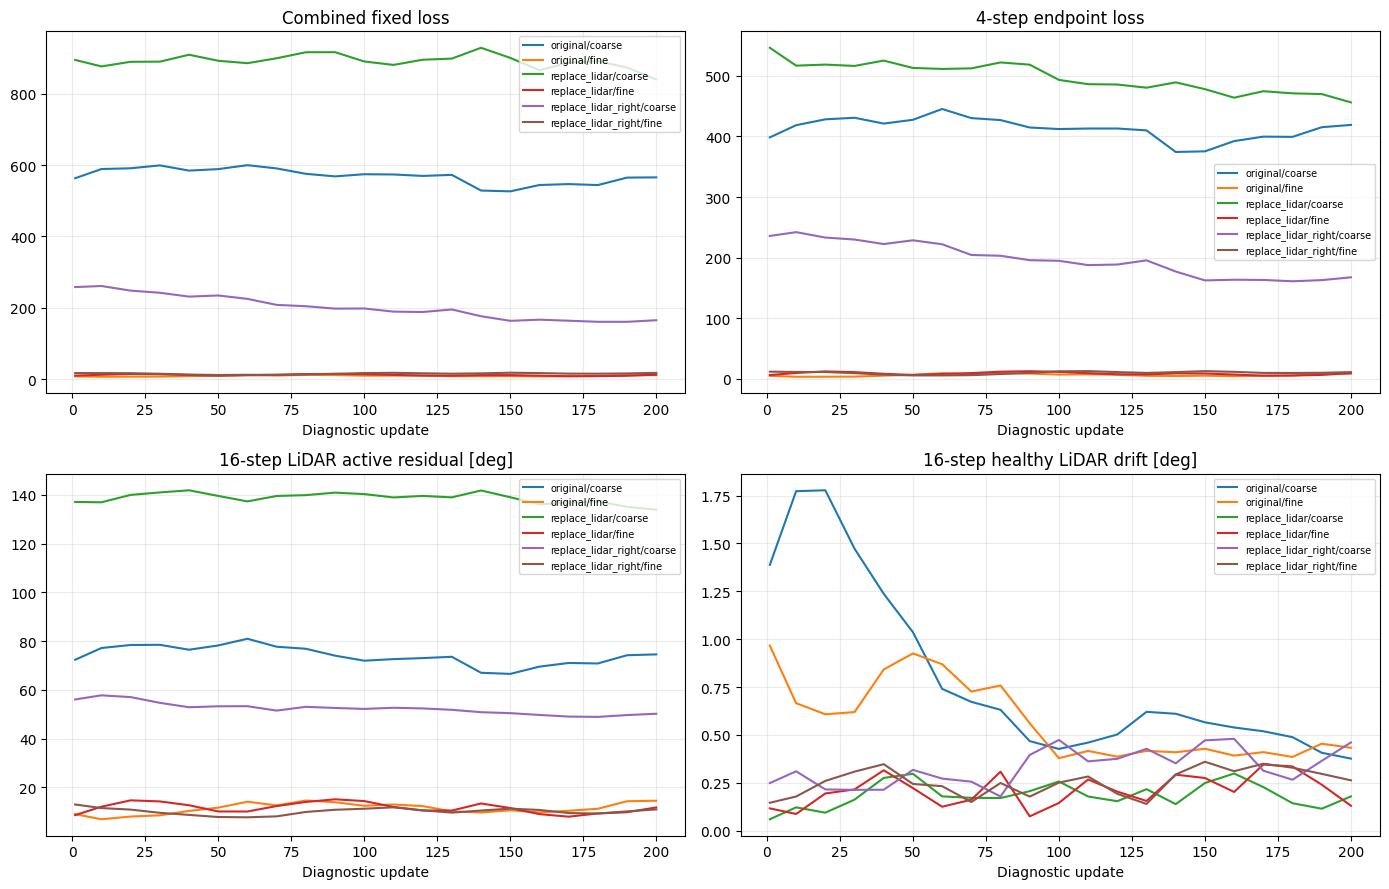

In [30]:
if precheck_history:
    check_df = pd.DataFrame(precheck_history)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for (mode, regime), part in check_df.groupby(["topology", "regime"]):
        line = f"{mode}/{regime}"
        axes[0, 0].plot(part.step, part.loss_combined_total, label=line)
        axes[0, 1].plot(part.step, part.loss_endpoint_total, label=line)
        if np.isfinite(part.inference_lidar_active_deg).any():
            axes[1, 0].plot(part.step, part.inference_lidar_active_deg, label=line)
        if np.isfinite(part.inference_lidar_healthy_deg).any():
            axes[1, 1].plot(part.step, part.inference_lidar_healthy_deg, label=line)
    for ax, title in zip(axes.flat, ("Combined fixed loss", "4-step endpoint loss", "16-step LiDAR active residual [deg]", "16-step healthy LiDAR drift [deg]")):
        ax.set(title=title, xlabel="Diagnostic update"); ax.grid(alpha=.25); ax.legend(fontsize=7)
    fig.tight_layout(); plt.show()
else:
    print("No stochastic-check history available")

## 9. Fixed, controlled angle-bin validation across all three topologies

In [15]:
ANGLE_EVAL_TOPOLOGIES = ("original", "replace_lidar", "replace_lidar_right")
ANGLE_EVAL_TOPOLOGY = "original"   # temporarily overridden inside build_all_angular_cases
ANGLE_EVAL_FAULT_KEYS = ("imu", "lidar", "lidar_right")
ANGLE_EVAL_BINS_DEG = ((0., 5.), (5., 15.), (15., 30.), (30., 60.), (60., 90.), (90., 120.), (120., 150.), (150., 179.))
ANGLE_EVAL_WINDOWS_PER_KEY = 4       # Number per (topology, angle bin, fault key): 3*8*3*4=288 one-step cases
ANGLE_EVAL_HEALTHY_WEIGHT = 0.25
ANGLE_EVAL_SEED = VAL_AUG_SEED + 950000
RUN_ANGLE_EVALUATION = True
RUN_ANGULAR_MODEL_COMPARISON = True
ANGLE_EVAL_OUTPUT = RUN_DIR / "fm51_fixed_angular_validation.csv"

@torch.no_grad()
def build_fixed_angular_cases():
    """Use controlled rotation-only prior errors on a fixed set of validation windows."""
    if ANGLE_EVAL_TOPOLOGY not in TOPOLOGY_MODES:
        raise ValueError(ANGLE_EVAL_TOPOLOGY)
    if not set(ANGLE_EVAL_FAULT_KEYS).issubset(EXPECTED_KEYS_BY_TOPOLOGY[ANGLE_EVAL_TOPOLOGY]):
        raise ValueError("Evaluation fault key is absent from the selected topology")
    indices = np.unique(np.linspace(0, len(val_dataset) - 1, ANGLE_EVAL_WINDOWS_PER_KEY).round().astype(int))
    cases = []
    for bin_index, (low, high) in enumerate(ANGLE_EVAL_BINS_DEG):
        if not (0 <= low < high < 180):
            raise ValueError((low, high))
        for key_index, faulty_key in enumerate(ANGLE_EVAL_FAULT_KEYS):
            for local_index, index in enumerate(indices):
                generator = augmentation_generator(VAL_AUG_SEED + 950000 + 100000 * bin_index + 10000 * key_index + local_index)
                base = window_batch_to(collate_windows([val_dataset[int(index)]]), DEVICE, dtype=DTYPE)
                physical = physical_augmenters[ANGLE_EVAL_TOPOLOGY](base, generator=generator).augmented_window
                truth = physical.current_calibration
                sample = next(iter(truth.values())).transform
                xi = {key: sample.new_zeros(1, 6) for key in truth}
                tau = {key: torch.zeros_like(state.time_offset) for key, state in truth.items()}
                axis = torch.randn(3, device=DEVICE, dtype=DTYPE, generator=generator)
                axis = axis / torch.linalg.vector_norm(axis).clamp_min(1e-12)
                angle_deg = float(low + (high - low) * torch.rand((), device=DEVICE, generator=generator).item())
                xi[faulty_key][0, :3] = axis * np.deg2rad(angle_deg)
                corrupted = clone_with_current_calibration(physical, apply_prior_perturbation(truth, xi, tau))
                target_xi, target_tau = correction_targets(corrupted)
                actual_angle = float(torch.rad2deg(torch.linalg.vector_norm(target_xi[faulty_key][0, :3])).item())
                if abs(actual_angle - angle_deg) > 0.25:
                    raise AssertionError(f"Controlled injection mismatch: expected {angle_deg:.3f}°, got {actual_angle:.3f}°")
                cases.append(dict(window=window_batch_to(corrupted, torch.device("cpu"), dtype=DTYPE),
                                  bin_label=f"{low:g}–{high:g}°", low=low, high=high,
                                  faulty_key=faulty_key, initial_deg=actual_angle, val_index=int(index)))
    return cases


@torch.no_grad()
def evaluate_fixed_angular_cases(model, cases, checkpoint_label):
    """Score the actual 16-step corrected physical extrinsics, including healthy drift."""
    previous_mode = model.training
    model.eval()
    rows = []
    try:
        for case in cases:
            window = window_batch_to(case["window"], DEVICE, dtype=DTYPE)
            tokens, context = tokenize_window(window)
            output = model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
            for key, prediction in output.predictions.items():
                current = window.current_calibration[key]
                desired = window.targets[key]
                corrected = se3_exp(prediction.delta_xi) @ current.transform
                residual = desired.next_transform @ torch.linalg.inv(corrected)
                rotation_error_deg = float(torch.rad2deg(torch.linalg.vector_norm(se3_log(residual)[:, :3], dim=-1)).mean())
                translation_error_cm = float((100.0 * torch.linalg.vector_norm(corrected[:, :3, 3] - desired.next_transform[:, :3, 3], dim=-1)).mean())
                tau_error_ms = float((1000.0 * torch.abs(current.time_offset + prediction.delta_tau - desired.next_time_offset)).mean())
                rows.append({"checkpoint": checkpoint_label, "topology": case["topology"], "bin": case["bin_label"],
                             "bin_low": case["low"], "bin_high": case["high"], "key": key,
                             "faulty_key": case["faulty_key"], "active": key == case["faulty_key"],
                             "initial_deg": case["initial_deg"], "val_index": case["val_index"],
                             "rotation_error_deg": rotation_error_deg, "translation_error_cm": translation_error_cm,
                             "tau_error_ms": tau_error_ms,
                             "improved": (rotation_error_deg < case["initial_deg"]) if key == case["faulty_key"] else False})
    finally:
        model.train(previous_mode)
    return pd.DataFrame(rows)


def summarize_angular_evaluation(records):
    active = records.loc[records.active].copy()
    if active.empty:
        raise RuntimeError("No active rotation-fault examples in fixed angular grid")
    result = active.groupby(["checkpoint", "topology", "bin", "bin_low", "bin_high"], sort=True, observed=True).agg(
        n=("rotation_error_deg", "size"),
        injected_mean_deg=("initial_deg", "mean"),
        final_mean_deg=("rotation_error_deg", "mean"),
        final_median_deg=("rotation_error_deg", "median"),
        final_p90_deg=("rotation_error_deg", lambda v: v.quantile(0.9)),
        improved_fraction=("improved", "mean"),
        translation_mean_cm=("translation_error_cm", "mean"),
        tau_mean_ms=("tau_error_ms", "mean"),
    ).reset_index().sort_values(["checkpoint", "topology", "bin_low"])
    return result


def score_angular_grid(records):
    """Comparable across ALL stages: uniform mean over fixed bins, not the changing train distribution."""
    active = summarize_angular_evaluation(records)
    per_bin = active.groupby(["topology", "bin"], sort=False)["final_mean_deg"].mean()
    healthy = records.loc[~records.active, "rotation_error_deg"]
    return float(per_bin.mean() + ANGLE_EVAL_HEALTHY_WEIGHT * healthy.mean())




@torch.no_grad()
def build_all_angular_cases(topologies=ANGLE_EVAL_TOPOLOGIES):
    global ANGLE_EVAL_TOPOLOGY, ANGLE_EVAL_FAULT_KEYS
    old_topology, old_keys = ANGLE_EVAL_TOPOLOGY, ANGLE_EVAL_FAULT_KEYS
    cases = []
    try:
        for topology in topologies:
            ANGLE_EVAL_TOPOLOGY = topology
            ANGLE_EVAL_FAULT_KEYS = tuple(sorted(EXPECTED_KEYS_BY_TOPOLOGY[topology]))
            for case in build_fixed_angular_cases():
                case["topology"] = topology
                cases.append(case)
    finally:
        ANGLE_EVAL_TOPOLOGY, ANGLE_EVAL_FAULT_KEYS = old_topology, old_keys
    return cases

fixed_angular_cases = build_all_angular_cases() if RUN_ANGLE_EVALUATION else []
print("Fixed angular cases:", len(fixed_angular_cases), "across", ANGLE_EVAL_TOPOLOGIES)

Fixed angular cases: 288 across ('original', 'replace_lidar', 'replace_lidar_right')


Evaluating FM50 source: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.7_angle_curriculum/best.pt


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Evaluating FM51 candidate: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/stochastic_topology_179deg.pt


,checkpoint,topology,bin,n,injected_mean_deg,final_mean_deg,final_p90_deg,improved_fraction
0,FM50 source,original,0–5°,12,3.179,2.410,4.710,0.667
5,FM50 source,original,5–15°,12,9.704,4.311,5.953,0.917
3,FM50 source,original,15–30°,12,22.686,4.823,7.308,1.000
4,FM50 source,original,30–60°,12,45.631,7.161,11.674,1.000
6,FM50 source,original,60–90°,12,75.198,21.744,38.114,1.000
7,FM50 source,original,90–120°,12,104.852,73.368,148.200,0.750
1,FM50 source,original,120–150°,12,136.234,114.014,177.379,0.583
2,FM50 source,original,150–179°,12,162.917,144.429,167.812,0.750
8,FM50 source,replace_lidar,0–5°,12,2.354,2.237,4.419,0.667
13,FM50 source,replace_lidar,5–15°,12,10.644,9.923,17.959,0.583


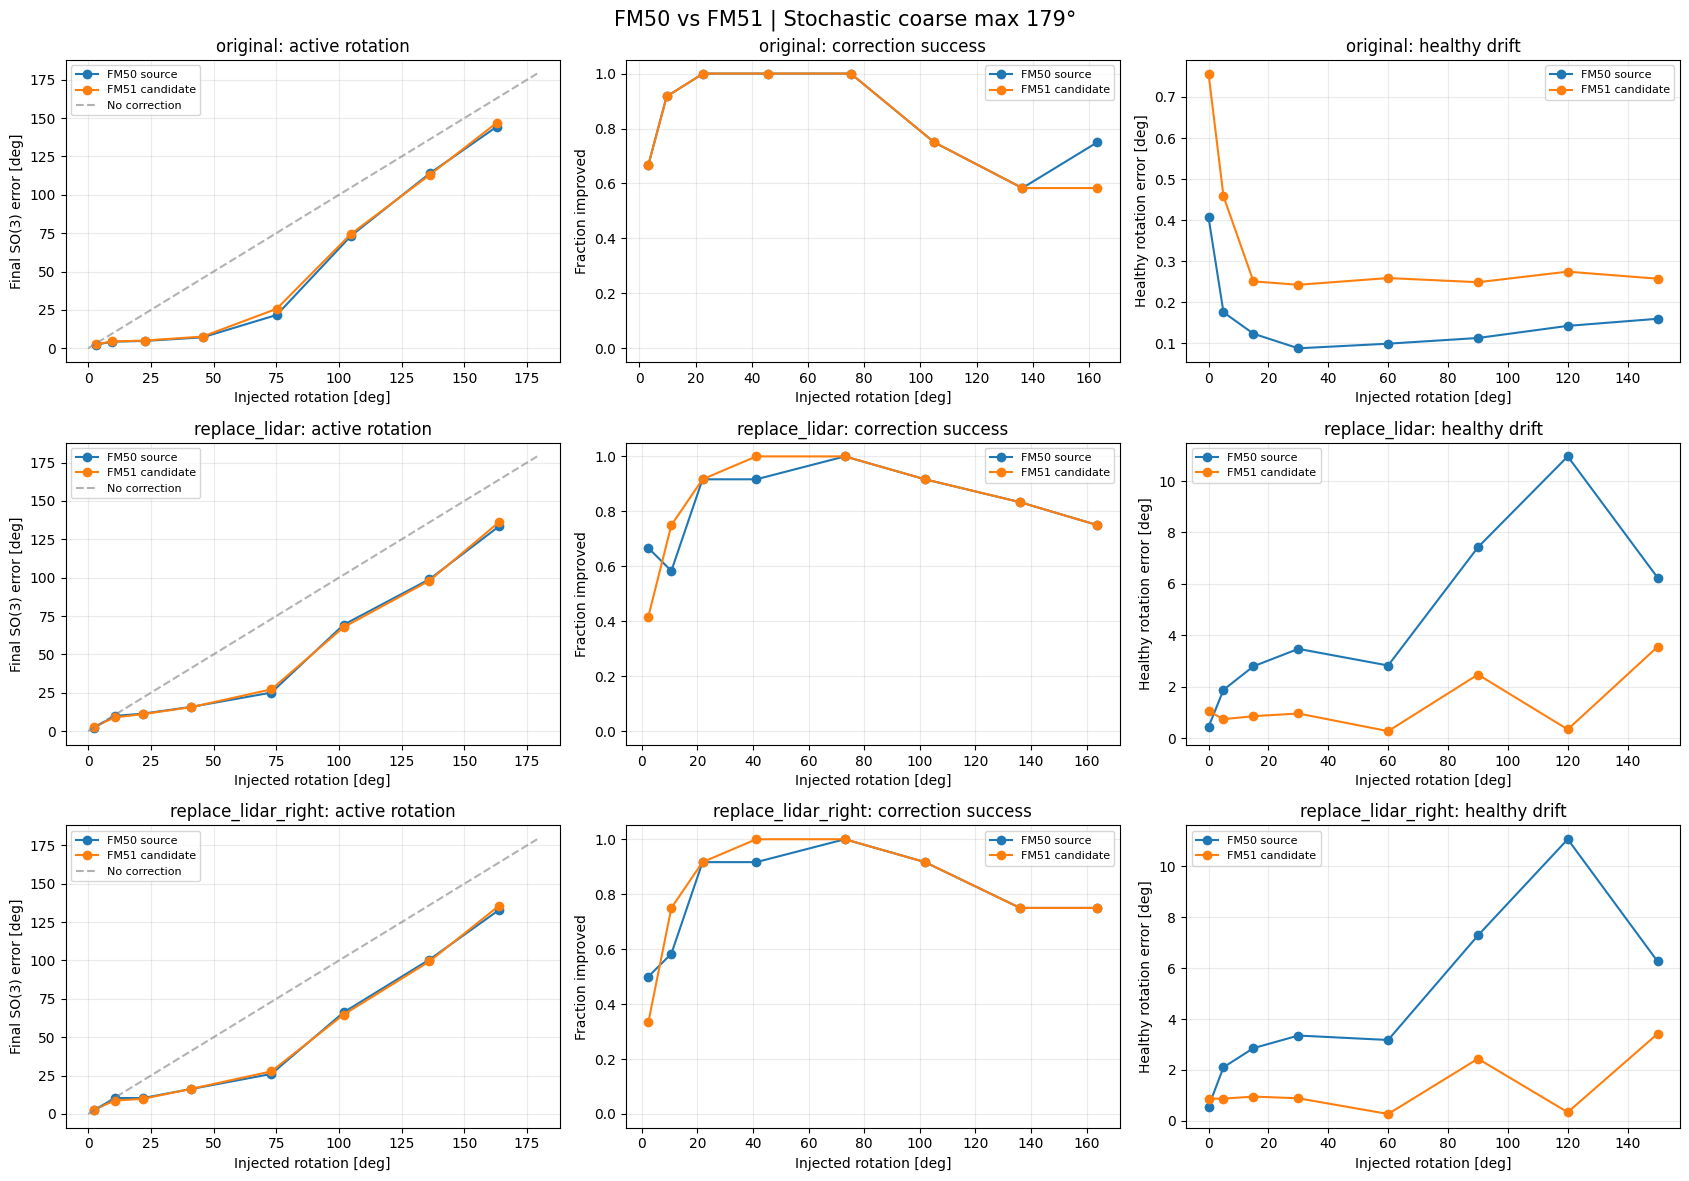

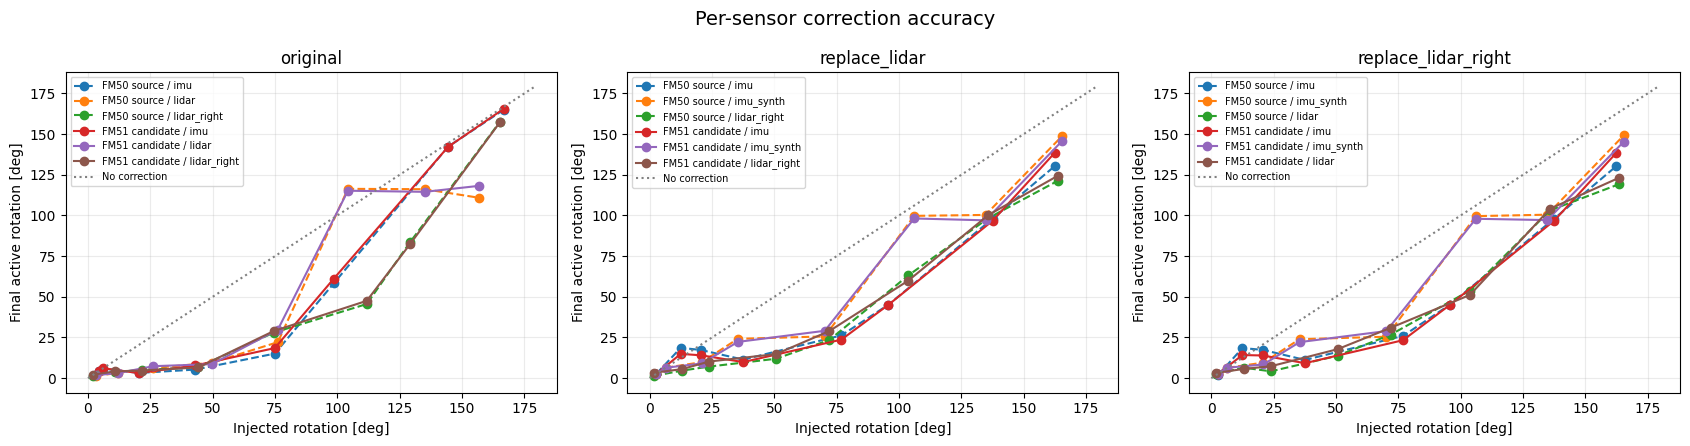

checkpoint                            FM50 source  FM51 candidate  delta_deg
topology            bin      bin_low                                        
original            0–5°     0.0            2.410           2.737      0.327
                    5–15°    5.0            4.311           4.470      0.159
                    15–30°   15.0           4.823           5.062      0.238
                    30–60°   30.0           7.161           7.657      0.497
                    60–90°   60.0          21.744          25.772      4.028
                    90–120°  90.0          73.368          74.586      1.218
                    120–150° 120.0        114.014         113.042     -0.971
                    150–179° 150.0        144.429         146.980      2.550
replace_lidar       0–5°     0.0            2.237           2.858      0.621
                    5–15°    5.0            9.923           8.971     -0.951
                    15–30°   15.0          11.403          11.095     -0.308
                    30–60°   30.0          15.832          15.643     -0.189
                    60–90°   60.0          25.121          27.233      2.111
                    90–120°  90.0          69.328          67.713     -1.615
                    120–150° 120.0         98.933          98.021     -0.912
                    150–179° 150.0        133.450         136.190      2.740
replace_lidar_right 0–5°     0.0            2.357           2.825      0.468
                    5–15°    5.0           10.428           8.761     -1.667
                    15–30°   15.0          10.381           9.893     -0.488
                    30–60°   30.0          16.299          16.376      0.077
                    60–90°   60.0          26.087          27.763      1.676
                    90–120°  90.0          66.209          64.727     -1.481
                    120–150° 120.0        100.574          99.384     -1.190
                    150–179° 150.0        132.944         135.668      2.724

FM50 angular score: 46.761
FM51 angular score: 46.633


In [29]:

# ================================================================
# FM50 vs FM51: fixed angular-grid comparison across topologies
# ================================================================

PLOT_CANDIDATE_CHECKPOINT = RUN_DIR / f"stochastic_topology_{STOCHASTIC_COARSE_MAX_DEG:g}deg.pt"
PLOT_PER_SENSOR = True

if not fixed_angular_cases:
    print("No fixed angular cases available.")
else:
    if not PLOT_CANDIDATE_CHECKPOINT.is_file():
        raise FileNotFoundError(f"FM51 candidate missing: {PLOT_CANDIDATE_CHECKPOINT}")

    saved_cpu_rng = torch.random.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None

    comparison_rows = []

    try:
        for label, checkpoint in (
            ("FM50 source", SOURCE_FM_CHECKPOINT),
            ("FM51 candidate", PLOT_CANDIDATE_CHECKPOINT),
        ):
            model = PooledCalibrationFlowModel(
                flow_config.backbone, **flow_config.model_kwargs()
            ).to(DEVICE, dtype=DTYPE)

            if checkpoint.name.startswith("stochastic_topology_"):
                state = torch.load(checkpoint, map_location="cpu", weights_only=False)
                model.load_state_dict(state["model_state_dict"], strict=True)
            else:
                load_training_checkpoint(
                    checkpoint, model=model, map_location=DEVICE,
                    restore_rng_state=False,
                )

            model.eval().requires_grad_(False)
            print(f"Evaluating {label}: {checkpoint}", flush=True)

            comparison_rows.append(
                evaluate_fixed_angular_cases(model, fixed_angular_cases, label)
            )

            del model
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

    finally:
        torch.random.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)

    angular_comparison = pd.concat(comparison_rows, ignore_index=True)
    angular_comparison.to_csv(ANGLE_EVAL_OUTPUT, index=False)

    angular_summary = summarize_angular_evaluation(angular_comparison)

    healthy_summary = (
        angular_comparison.loc[~angular_comparison.active]
        .groupby(["checkpoint", "topology", "bin_low"], as_index=False)
        .agg(healthy_mean_deg=("rotation_error_deg", "mean"))
    )

    display(
        angular_summary[
            ["checkpoint", "topology", "bin", "n",
             "injected_mean_deg", "final_mean_deg",
             "final_p90_deg", "improved_fraction"]
        ].round(3)
    )

    # ------------------------------------------------------------
    # Figure 1: one row per topology, three performance metrics
    # ------------------------------------------------------------

    fig, axes = plt.subplots(
        len(ANGLE_EVAL_TOPOLOGIES), 3,
        figsize=(17, 12), squeeze=False,
    )

    for row_idx, topology in enumerate(ANGLE_EVAL_TOPOLOGIES):
        subset = angular_summary[angular_summary.topology == topology]

        for label, part in subset.groupby("checkpoint"):
            part = part.sort_values("bin_low")

            x = part.injected_mean_deg.to_numpy()

            axes[row_idx, 0].plot(
                x, part.final_mean_deg,
                "-o", label=label,
            )

            axes[row_idx, 1].plot(
                x, part.improved_fraction,
                "-o", label=label,
            )

            healthy = healthy_summary[
                (healthy_summary.topology == topology) &
                (healthy_summary.checkpoint == label)
            ].sort_values("bin_low")

            axes[row_idx, 2].plot(
                healthy.bin_low.to_numpy(),
                healthy.healthy_mean_deg.to_numpy(),
                "-o", label=label,
            )

        axes[row_idx, 0].plot(
            [0, 179], [0, 179],
            "--", color="gray", alpha=0.6,
            label="No correction",
        )

        axes[row_idx, 0].set_title(f"{topology}: active rotation")
        axes[row_idx, 1].set_title(f"{topology}: correction success")
        axes[row_idx, 2].set_title(f"{topology}: healthy drift")

        axes[row_idx, 0].set_ylabel("Final SO(3) error [deg]")
        axes[row_idx, 1].set_ylabel("Fraction improved")
        axes[row_idx, 2].set_ylabel("Healthy rotation error [deg]")

        axes[row_idx, 1].set_ylim(-0.05, 1.05)

        for ax in axes[row_idx]:
            ax.set_xlabel("Injected rotation [deg]")
            ax.grid(alpha=0.25)
            ax.legend(fontsize=8)

    fig.suptitle(
        f"FM50 vs FM51 | Stochastic coarse max {STOCHASTIC_COARSE_MAX_DEG:g}°",
        fontsize=15,
    )
    fig.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # Figure 2: active rotation errors for individual fault keys
    # ------------------------------------------------------------

    if PLOT_PER_SENSOR:
        fig, axes = plt.subplots(
            1, len(ANGLE_EVAL_TOPOLOGIES),
            figsize=(17, 4.5), squeeze=False,
        )

        for ax, topology in zip(axes[0], ANGLE_EVAL_TOPOLOGIES):
            subset = angular_comparison[
                angular_comparison.active &
                (angular_comparison.topology == topology)
            ]

            grouped = (
                subset.groupby(
                    ["checkpoint", "faulty_key", "bin_low"],
                    as_index=False,
                )
                .agg(
                    injected_deg=("initial_deg", "mean"),
                    final_deg=("rotation_error_deg", "mean"),
                )
            )

            for (label, key), part in grouped.groupby(
                ["checkpoint", "faulty_key"]
            ):
                part = part.sort_values("bin_low")

                ax.plot(
                    part.injected_deg,
                    part.final_deg,
                    marker="o",
                    linestyle="-" if label == "FM51 candidate" else "--",
                    label=f"{label} / {key}",
                )

            ax.plot(
                [0, 179], [0, 179],
                ":", color="gray", label="No correction",
            )

            ax.set(
                title=topology,
                xlabel="Injected rotation [deg]",
                ylabel="Final active rotation [deg]",
            )
            ax.grid(alpha=0.25)
            ax.legend(fontsize=7)

        fig.suptitle("Per-sensor correction accuracy", fontsize=14)
        fig.tight_layout()
        plt.show()

    # ------------------------------------------------------------
    # Paired numerical comparison: negative delta is improvement
    # ------------------------------------------------------------

    paired = angular_summary.pivot_table(
        index=["topology", "bin", "bin_low"],
        columns="checkpoint",
        values="final_mean_deg",
    )

    paired["delta_deg"] = (
        paired["FM51 candidate"] - paired["FM50 source"]
    )

    display(paired.sort_index(level=["topology", "bin_low"]).round(3))

    print("FM50 angular score:", round(
        score_angular_grid(
            angular_comparison[angular_comparison.checkpoint == "FM50 source"]
        ), 3,
    ))
    print("FM51 angular score:", round(
        score_angular_grid(
            angular_comparison[angular_comparison.checkpoint == "FM51 candidate"]
        ), 3,
    ))


## 10. FM51 full training, checkpointing and stage-independent model selection

In [31]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()

In [34]:
# Full-training checkpoint selection uses the weighted validation objective.
# The fixed per-topology angular grid is evaluated separately for comparison.
# FULL training never inherits stochastic candidate weights unless SOURCE_FM_CHECKPOINT
# is explicitly changed by you (not recommended for a clean experiment).

history = []
start_epoch, global_step = 0, 0
best_val = float("inf")
if RESUME_FULL_TRAINING and LAST_CHECKPOINT_PATH.is_file():
    load_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer,
                             scheduler=scheduler, map_location=DEVICE, restore_rng_state=True)
    checkpoint_data = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    start_epoch = int(checkpoint_data["epoch"])
    global_step = int(checkpoint_data["global_step"])
    extra = checkpoint_data.get("extra_state") or {}
    if float(extra.get("full_coarse_max_deg", FULL_COARSE_MAX_DEG)) != FULL_COARSE_MAX_DEG:
        raise ValueError("Cannot resume after changing FULL_COARSE_MAX_DEG; use a separate RUN_NAME")
    if tuple(extra.get("loss_weights", (FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT))) != (FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT):
        raise ValueError("Cannot resume after changing regime loss weights; use a separate RUN_NAME")
    best_val = float(extra.get("best_val", float("inf")))
    print("Resumed FM51 full run:", start_epoch, "epochs, global step", global_step)
else:
    load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
    if FULL_INIT_FROM_STOCHASTIC_CANDIDATE:
        warm_path = RUN_DIR / f"stochastic_topology_{FULL_STOCHASTIC_INIT_ANGLE_DEG:g}deg.pt"
        if not warm_path.is_file():
            raise FileNotFoundError(warm_path)
        warm_data = torch.load(warm_path, map_location="cpu", weights_only=False)
        fm_model.load_state_dict(warm_data["model_state_dict"], strict=True)
        print("Fresh FM51 full run warm-started from stochastic weights:", warm_path)
    else:
        print("Fresh FM51 full run initialized from:", SOURCE_FM_CHECKPOINT)

set_coarse_angle(FULL_COARSE_MAX_DEG)


def save_fm51_checkpoint(path, epoch, metrics):
    save_training_checkpoint(path, model=fm_model, optimizer=optimizer, scheduler=scheduler,
                             epoch=epoch, global_step=global_step, metrics=metrics,
                             extra_state={"source_checkpoint": str(SOURCE_FM_CHECKPOINT),
                                          "full_coarse_max_deg": FULL_COARSE_MAX_DEG,
                                          "train_topology": FULL_TRAIN_TOPOLOGY,
                                          "train_regime": FULL_TRAIN_REGIME,
                                          "loss_weights": (FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT),
                                          "best_val": best_val})

if RUN_FULL_TRAINING:
    if REQUIRE_PRECHECK_PASS_FOR_FULL_TRAINING and STOCHASTIC_CHECK_PASSED is not True:
        raise RuntimeError("Stochastic preflight did not pass")
    for epoch in range(start_epoch, TRAIN_EPOCHS):
        train_shuffle_generator.manual_seed(SEED + 12001 + epoch)
        train_m = run_topology_fm_epoch(train_loader, training=True, seed=TRAIN_AUG_SEED + 100003 * epoch,
                                        topology=FULL_TRAIN_TOPOLOGY, regime=FULL_TRAIN_REGIME,
                                        max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val_m = run_topology_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED,
                                      topology=FULL_TRAIN_TOPOLOGY, regime=FULL_TRAIN_REGIME,
                                      max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        val_objective = float(val_m["loss_weighted_total"])
        scheduler.step(val_objective)
        global_step += int(train_m["optimizer_steps"])
        improved = val_objective < best_val
        if improved:
            best_val = val_objective
        row = {"epoch": epoch + 1, "train_combined": train_m["loss_combined_total"],
               "val_combined": val_m["loss_combined_total"],
               "train_weighted": train_m["loss_weighted_total"],
               "val_weighted": val_objective,
               "train_velocity": train_m["loss_fm_total"], "val_velocity": val_m["loss_fm_total"],
               "train_endpoint": train_m["loss_endpoint_total"], "val_endpoint": val_m["loss_endpoint_total"]}
        history.append(row)
        pd.DataFrame(history).to_csv(RUN_DIR / "fm51_full_history.csv", index=False)
        if improved:
            save_fm51_checkpoint(BEST_CHECKPOINT_PATH, epoch + 1, val_m)
        save_fm51_checkpoint(LAST_CHECKPOINT_PATH, epoch + 1, val_m)
        print(f"Epoch {epoch+1:3d}/{TRAIN_EPOCHS} | coarse max={FULL_COARSE_MAX_DEG:g}° "
              f"train={train_m['loss_weighted_total']:.3f} val={val_objective:.3f} "
              f"unweighted val={val_m['loss_combined_total']:.3f} "
              f"LR={optimizer.param_groups[0]['lr']:.1e}/{optimizer.param_groups[1]['lr']:.1e} "
              + ("BEST" if improved else ""), flush=True)
else:
    print("Full training is OFF; the stochastic candidate can be evaluated separately.")

Fresh FM51 full run initialized from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.7_angle_curriculum/best.pt
Epoch   1/200 | coarse max=179° train=231.674 val=213.357 unweighted val=213.357 LR=3.0e-05/3.0e-06 BEST
Epoch   2/200 | coarse max=179° train=204.119 val=211.244 unweighted val=211.244 LR=3.0e-05/3.0e-06 BEST
Epoch   3/200 | coarse max=179° train=203.800 val=211.512 unweighted val=211.512 LR=3.0e-05/3.0e-06 
Epoch   4/200 | coarse max=179° train=202.066 val=210.431 unweighted val=210.431 LR=3.0e-05/3.0e-06 BEST
Epoch   5/200 | coarse max=179° train=207.930 val=210.162 unweighted val=210.162 LR=3.0e-05/3.0e-06 BEST
Epoch   6/200 | coarse max=179° train=216.042 val=208.136 unweighted val=208.136 LR=3.0e-05/3.0e-06 BEST
Epoch   7/200 | coarse max=179° train=193.400 val=206.228 unweighted val=206.228 LR=3.0e-05/3.0e-06 BEST
Epoch   8/200 | coarse max=179° train=227.805 val=205.890 unweighted val=205.890 LR=3.0e-05/3.0e-06 BEST
Epoch   9/20

KeyboardInterrupt: 

## 11. Select checkpoints for the paired evaluation

In [35]:
# Choose "stochastic", "best", or "last". This selection NEVER changes full-training resume state.
EVALUATE_FM51_FROM = "best"
EVALUATE_STOCHASTIC_ANGLE_DEG = STOCHASTIC_COARSE_MAX_DEG
RUN_EVALUATION = True

def evaluated_fm51_checkpoint():
    if EVALUATE_FM51_FROM == "stochastic":
        return RUN_DIR / f"stochastic_topology_{EVALUATE_STOCHASTIC_ANGLE_DEG:g}deg.pt"
    if EVALUATE_FM51_FROM == "best":
        return BEST_CHECKPOINT_PATH
    if EVALUATE_FM51_FROM == "last":
        return LAST_CHECKPOINT_PATH
    raise ValueError(EVALUATE_FM51_FROM)

FM51_EVAL_CHECKPOINT = evaluated_fm51_checkpoint()
print("Source:", SOURCE_FM_CHECKPOINT)
print("Candidate:", FM51_EVAL_CHECKPOINT, "exists:", FM51_EVAL_CHECKPOINT.is_file())

# Load candidate only into an INDEPENDENT model; never overwrite fm_model, optimizer or scheduler.
def load_fm51_candidate(path):
    if not path.is_file():
        raise FileNotFoundError(path)
    candidate = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=DTYPE)
    if path.name.startswith("stochastic_topology_"):
        data = torch.load(path, map_location="cpu", weights_only=False)
        candidate.load_state_dict(data["model_state_dict"], strict=True)
    else:
        load_training_checkpoint(path, model=candidate, map_location=DEVICE, restore_rng_state=False)
    return candidate.eval().requires_grad_(False)


def load_source_fm50():
    baseline = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=DTYPE)
    load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=baseline, map_location=DEVICE, restore_rng_state=False)
    return baseline.eval().requires_grad_(False)

Source: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.7_angle_curriculum/best.pt
Candidate: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/best.pt exists: True


## 12. Paired angular-bin evaluation across topologies (validation only)

,checkpoint,topology,bin,n,injected_mean_deg,final_mean_deg,final_p90_deg,improved_fraction
0,FM50 source,original,0–5°,12,3.179,2.410,4.710,0.667
5,FM50 source,original,5–15°,12,9.704,4.311,5.953,0.917
3,FM50 source,original,15–30°,12,22.686,4.823,7.308,1.000
4,FM50 source,original,30–60°,12,45.631,7.161,11.674,1.000
6,FM50 source,original,60–90°,12,75.198,21.744,38.114,1.000
7,FM50 source,original,90–120°,12,104.852,73.368,148.200,0.750
1,FM50 source,original,120–150°,12,136.234,114.014,177.379,0.583
2,FM50 source,original,150–179°,12,162.917,144.429,167.812,0.750
8,FM50 source,replace_lidar,0–5°,12,2.354,2.237,4.419,0.667
13,FM50 source,replace_lidar,5–15°,12,10.644,9.923,17.959,0.583


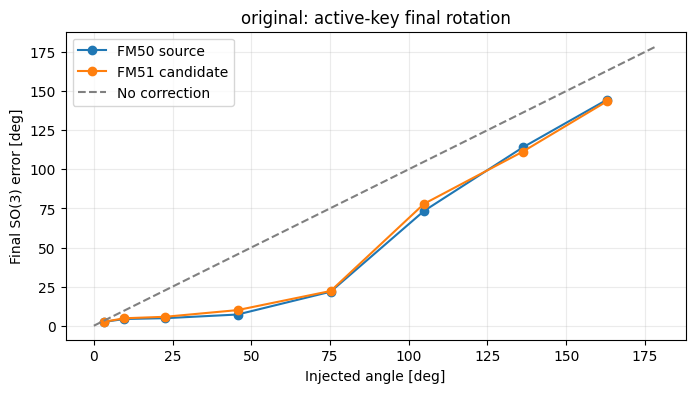

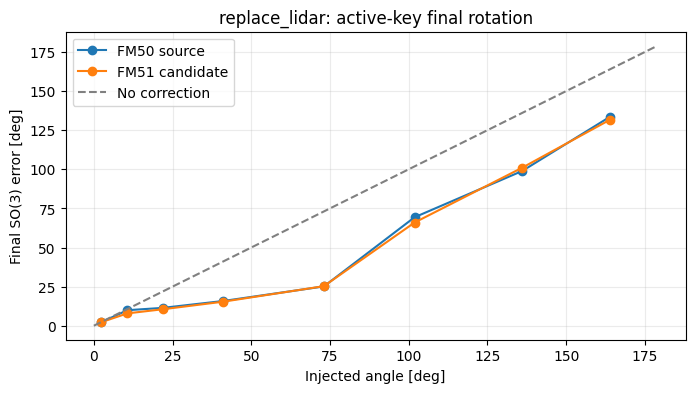

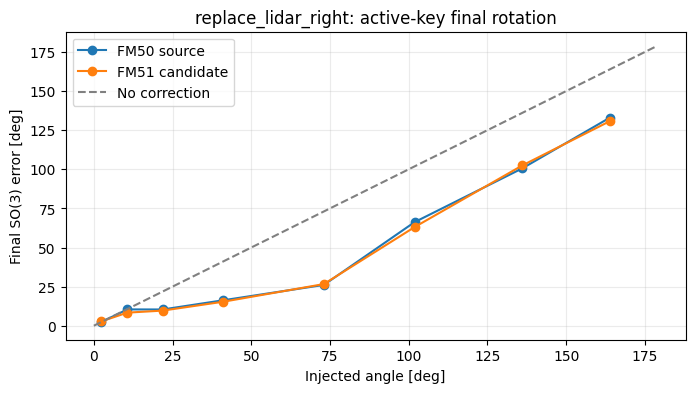

In [36]:
if RUN_EVALUATION and RUN_ANGULAR_MODEL_COMPARISON and FM51_EVAL_CHECKPOINT.is_file():
    comparison_rows = []
    for label, loader_fn in (("FM50 source", load_source_fm50),
                             ("FM51 candidate", lambda: load_fm51_candidate(FM51_EVAL_CHECKPOINT))):
        comparison_model = loader_fn()
        comparison_rows.append(evaluate_fixed_angular_cases(comparison_model, fixed_angular_cases, label))
        del comparison_model
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    angular_comparison = pd.concat(comparison_rows, ignore_index=True)
    angular_comparison.to_csv(ANGLE_EVAL_OUTPUT, index=False)
    angular_summary = summarize_angular_evaluation(angular_comparison)
    display(angular_summary[["checkpoint", "topology", "bin", "n", "injected_mean_deg", "final_mean_deg", "final_p90_deg", "improved_fraction"]].round(3))
    for topology in ANGLE_EVAL_TOPOLOGIES:
        fig, ax = plt.subplots(figsize=(8, 4))
        for label, part in angular_summary[angular_summary.topology == topology].groupby("checkpoint"):
            part = part.sort_values("bin_low")
            ax.plot(part.injected_mean_deg, part.final_mean_deg, "-o", label=label)
        ax.plot([0,179], [0,179], "--", color="gray", label="No correction")
        ax.set(title=f"{topology}: active-key final rotation", xlabel="Injected angle [deg]", ylabel="Final SO(3) error [deg]")
        ax.grid(alpha=.25); ax.legend(); plt.show()
else:
    print("Angular comparison skipped: enable RUN_EVALUATION and create the candidate checkpoint first.")

## 13. Chronological calibration rollouts, averaged across multiple starting windows

**Not** FM integration steps. Each outer step consumes a *new 5-second physical IMU/LiDAR window*; the estimated extrinsic from the previous window becomes the next prior. Both models receive identical windows, faulty sensor and initial axis-angle. No ground-truth reset during a rollout.

The physical augmentation of synthetic topologies is repeated with a fixed seed and **rig consistency is asserted**. If the synthetic mounting or true calibration varies across windows, the notebook raises instead of plotting an invalid sequential experiment. Start with `ROLLOUT_TOPOLOGIES=("original",)` for the simplest reliable check.

In [37]:
from obscalib.geometry.lie import so3_exp

RUN_PHYSICAL_ROLLOUTS = True
ROLLOUT_TOPOLOGIES = ("original",)   # Add synthetic modes only after the consistency assertion passes
ROLLOUT_SEQUENCES = tuple(VAL_NAMES)  # Validation recordings, not the test recordings
ROLLOUT_STARTS_PER_SEQUENCE = 2
ROLLOUT_NUM_WINDOWS = 12
ROLLOUT_FAULT_KEYS = ("lidar",)       # Expand to ("imu", "lidar", "lidar_right") for full evaluation
ROLLOUT_INITIAL_ANGLES_DEG = (0.0, 15.0, 45.0, 60.0, 90.0, 120.0, 150.0, 179.0)
ROLLOUT_AXIS_SEEDS = 1              # Increase to 3 for uncertainty across axes
ROLLOUT_UPDATE_ALL_KEYS = True      # False = oracle isolation: update only the intentionally corrupted key
ROLLOUT_ROTATION_GAIN = 1.0
ROLLOUT_TRANSLATION_GAIN = 1.0
ROLLOUT_TAU_GAIN = 1.0
ROLLOUT_MAX_ROTATION_STEP_DEG = None # None = unconstrained full SE(3) update
ROLLOUT_MAX_TRANSLATION_STEP_M = None
ROLLOUT_MAX_TAU_STEP_MS = None
ROLLOUT_SHOW_INDIVIDUAL = False
ROLLOUT_PHYSICAL_SEED = VAL_AUG_SEED + 1200000
ROLLOUT_ERROR_PERCENTILES = (0.1, 0.9)


def clone_calibration_states(states):
    return {key: replace(state, transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone())
            for key, state in states.items()}


def rotation_error_deg(T, truth):
    R = truth[..., :3, :3] @ T[..., :3, :3].transpose(-1, -2)
    skew = torch.stack((R[...,2,1]-R[...,1,2], R[...,0,2]-R[...,2,0], R[...,1,0]-R[...,0,1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5*torch.linalg.vector_norm(skew,dim=-1),
                                    0.5*(R.diagonal(dim1=-2,dim2=-1).sum(dim=-1)-1.0)))


def bounded_vector(x, maximum):
    if maximum is None:
        return x
    norm = torch.linalg.vector_norm(x, dim=-1, keepdim=True).clamp_min(1e-12)
    return x * (float(maximum) / norm).clamp(max=1.0)


def fixed_physical_rollout_windows(sequence, start, topology, length):
    indices = np.asarray(val_dataset.window_indices_for_sequence(sequence), dtype=int)
    selected = indices[start:start + length]
    if len(selected) != length:
        raise ValueError(f"Insufficient windows for {sequence}, start {start}: {len(selected)} < {length}")
    physical_windows = []
    for index in selected:
        raw = window_batch_to(collate_windows([val_dataset[int(index)]]), DEVICE, dtype=DTYPE)
        if topology == "original":
            physical = raw                    # Nominal real-sensor rig, no randomized true-calibration augmentation
        else:
            physical = physical_augmenters[topology](raw, generator=augmentation_generator(ROLLOUT_PHYSICAL_SEED + 100 * TOPOLOGY_MODES.index(topology) + start))
        physical_windows.append(physical)
    nominal_truth = physical_windows[0].current_calibration
    for step, window in enumerate(physical_windows):
        if frozenset(window.current_calibration) != EXPECTED_KEYS_BY_TOPOLOGY[topology]:
            raise AssertionError((topology, step, tuple(window.current_calibration)))
        for key in nominal_truth:
            torch.testing.assert_close(window.current_calibration[key].transform, nominal_truth[key].transform,
                                       atol=2e-5, rtol=2e-5, msg=f"Physical rig changed across {topology} windows: key={key}, step={step}")
            torch.testing.assert_close(window.current_calibration[key].time_offset, nominal_truth[key].time_offset,
                                       atol=2e-6, rtol=2e-6)
    return selected, physical_windows, nominal_truth


def rollout_start_positions(sequence, count, length):
    indices = np.asarray(val_dataset.window_indices_for_sequence(sequence), dtype=int)
    last_start = len(indices) - length
    if last_start < 0:
        return []
    return sorted(set(np.linspace(0, last_start, min(count, last_start + 1)).round().astype(int).tolist()))


def sample_rollout_axis(sequence, start, key, axis_index):
    # Local NumPy RNG: stable axes shared across both models and future experiments.
    key_index = ("imu", "lidar", "lidar_right", "imu_synth").index(key)
    seed = ROLLOUT_PHYSICAL_SEED + 990001 + 10007*ROLLOUT_SEQUENCES.index(sequence) + 263*start + 31*key_index + axis_index
    rng = np.random.default_rng(seed)
    axis = rng.standard_normal(3)
    return axis / np.linalg.norm(axis)


def initial_fault_states(truth, key, angle_deg, axis):
    states = clone_calibration_states(truth)
    reference = states[key]
    rotvec = reference.transform.new_tensor(axis).reshape(1,3) * float(np.deg2rad(angle_deg))
    T = reference.transform.clone()
    T[..., :3, :3] = so3_exp(rotvec) @ T[..., :3, :3]
    states[key] = replace(reference, transform=T)
    actual = float(rotation_error_deg(T, truth[key].transform).item())
    assert abs(actual-angle_deg) < 0.06, (key, angle_deg, actual)
    return states


def apply_fm_rollout_update(states, predictions, fault_key):
    """Use SE(3) left-multiplicative updates, with optional isolated-key control."""
    updated = clone_calibration_states(states)
    for key, state in states.items():
        if not ROLLOUT_UPDATE_ALL_KEYS and key != fault_key:
            continue
        pred = predictions[key]
        dr = bounded_vector(ROLLOUT_ROTATION_GAIN * pred.delta_xi[..., :3],
                            None if ROLLOUT_MAX_ROTATION_STEP_DEG is None else np.deg2rad(ROLLOUT_MAX_ROTATION_STEP_DEG))
        dp = bounded_vector(ROLLOUT_TRANSLATION_GAIN * pred.delta_xi[..., 3:], ROLLOUT_MAX_TRANSLATION_STEP_M)
        correction = se3_exp(torch.cat((dr, dp), dim=-1))
        tau_increment = bounded_vector(ROLLOUT_TAU_GAIN * pred.delta_tau,
                                       None if ROLLOUT_MAX_TAU_STEP_MS is None else ROLLOUT_MAX_TAU_STEP_MS/1000.0)
        updated[key] = replace(state, transform=correction @ state.transform, time_offset=state.time_offset + tau_increment)
    return updated


def calibration_rollout_rows(states, truth, *, model, topology, sequence, start, angle_deg, axis_id, fault_key, step, index):
    rows = []
    for key in truth:
        state, ref = states[key], truth[key]
        rows.append(dict(model=model, topology=topology, sequence=sequence, start=start,
                         initial_deg=angle_deg, axis_id=axis_id, fault_key=fault_key,
                         key=key, active=(key==fault_key), step=step, window_index=index,
                         rotation_error_deg=float(rotation_error_deg(state.transform, ref.transform).item()),
                         translation_error_cm=float((100 * torch.linalg.vector_norm(state.transform[..., :3,3]-ref.transform[..., :3,3], dim=-1)).mean().item()),
                         tau_error_ms=float((1000*torch.abs(state.time_offset-ref.time_offset)).mean().item())))
    return rows


@torch.inference_mode()
def evaluate_chronological_rollout(model, name, windows, indices, truth, initial, *, topology, sequence, start, angle, axis_id, fault_key):
    states = clone_calibration_states(initial)
    results = calibration_rollout_rows(states, truth, model=name, topology=topology, sequence=sequence,
                                       start=start, angle_deg=angle, axis_id=axis_id, fault_key=fault_key,
                                       step=0, index=-1)
    model.eval()
    for step, (index, physical) in enumerate(zip(indices, windows), 1):
        hypothesis = clone_with_current_calibration(physical, states)
        output = model_predictions(model, hypothesis, steps=FM_INTEGRATION_STEPS)
        states = apply_fm_rollout_update(states, output.predictions, fault_key)
        results.extend(calibration_rollout_rows(states, truth, model=name, topology=topology, sequence=sequence,
                                                 start=start, angle_deg=angle, axis_id=axis_id, fault_key=fault_key,
                                                 step=step, index=int(index)))
    return results

## 14. Run matched FM50/FМ51 multi-window rollouts, aggregate over starting windows

In [38]:
ROLLOUT_OUTPUT = RUN_DIR / f"fm51_rollouts_{EVALUATE_FM51_FROM}_{EVALUATE_STOCHASTIC_ANGLE_DEG:g}deg.csv"
if RUN_PHYSICAL_ROLLOUTS and RUN_EVALUATION and FM51_EVAL_CHECKPOINT.is_file():
    baseline = load_source_fm50()
    candidate = load_fm51_candidate(FM51_EVAL_CHECKPOINT)
    rollout_rows = []
    cases_count = 0
    try:
        for topology in ROLLOUT_TOPOLOGIES:
            for sequence in ROLLOUT_SEQUENCES:
                for start in rollout_start_positions(sequence, ROLLOUT_STARTS_PER_SEQUENCE, ROLLOUT_NUM_WINDOWS):
                    indices, windows, truth = fixed_physical_rollout_windows(sequence, start, topology, ROLLOUT_NUM_WINDOWS)
                    for fault_key in ROLLOUT_FAULT_KEYS:
                        if fault_key not in truth:
                            continue
                        for axis_id in range(ROLLOUT_AXIS_SEEDS):
                            axis = sample_rollout_axis(sequence, start, fault_key, axis_id)
                            for angle in ROLLOUT_INITIAL_ANGLES_DEG:
                                initial = initial_fault_states(truth, fault_key, angle, axis)
                                for name, model in (("FM50 source", baseline), ("FM51 candidate", candidate)):
                                    rollout_rows.extend(evaluate_chronological_rollout(
                                        model, name, windows, indices, truth, initial,
                                        topology=topology, sequence=sequence, start=start,
                                        angle=angle, axis_id=axis_id, fault_key=fault_key))
                                cases_count += 1
                    print("Rollout complete:", topology, sequence, "start", start, "cases so far", cases_count, flush=True)
        rollout_df = pd.DataFrame.from_records(rollout_rows)
        rollout_df.to_csv(ROLLOUT_OUTPUT, index=False)
    finally:
        del baseline, candidate
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    print("Paired scenarios:", cases_count, "| rows:", len(rollout_df), "| saved", ROLLOUT_OUTPUT)
else:
    print("Physical rollouts skipped or candidate not found.")

Rollout complete: original Urban26 start 0 cases so far 8
Rollout complete: original Urban26 start 82 cases so far 16
Rollout complete: original Urban28 start 0 cases so far 24
Rollout complete: original Urban28 start 312 cases so far 32
Paired scenarios: 32 | rows: 2496 | saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.8_topology_179/fm51_rollouts_best_179deg.csv


## 15. Rollout plots: mean and spread across starting windows and axes, including healthy drift

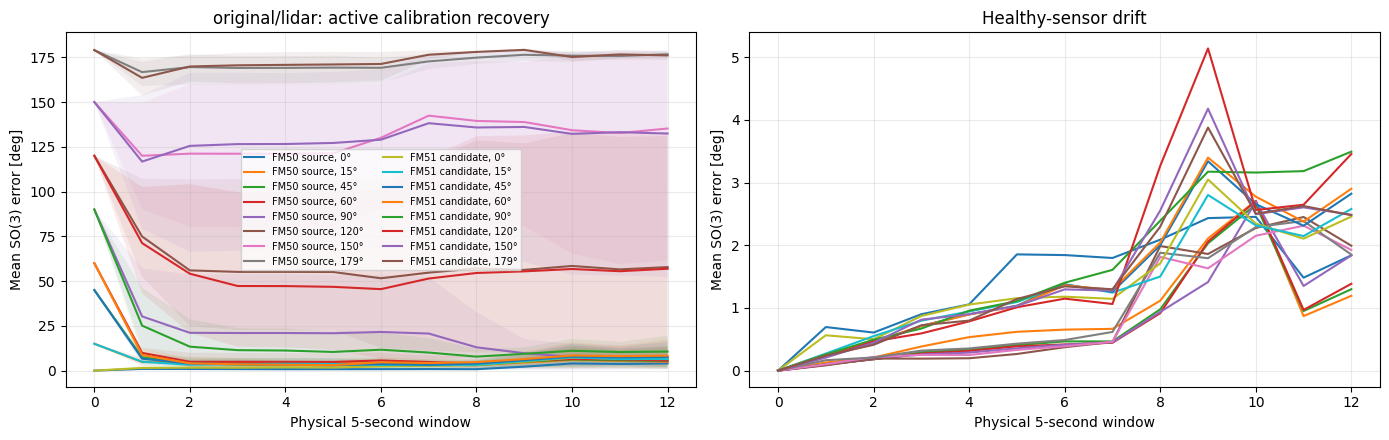

,topology,fault_key,initial_deg,model,n,mean_final_deg,median_final_deg,success_under_5_deg,improved_fraction
0,original,lidar,0.0,FM50 source,4,3.999,1.053,0.75,0.00
1,original,lidar,0.0,FM51 candidate,4,6.608,4.066,0.50,0.00
2,original,lidar,15.0,FM50 source,4,5.014,2.177,0.75,1.00
3,original,lidar,15.0,FM51 candidate,4,6.448,2.849,0.75,0.75
4,original,lidar,45.0,FM50 source,4,5.402,1.570,0.75,1.00
5,original,lidar,45.0,FM51 candidate,4,7.631,3.482,0.75,1.00
6,original,lidar,60.0,FM50 source,4,5.630,1.810,0.75,1.00
7,original,lidar,60.0,FM51 candidate,4,8.359,4.106,0.50,1.00
8,original,lidar,90.0,FM50 source,4,7.454,3.689,0.75,1.00
9,original,lidar,90.0,FM51 candidate,4,10.627,6.339,0.25,1.00


In [39]:
if "rollout_df" in globals() and not rollout_df.empty:
    grouped = rollout_df.groupby(["topology", "model", "fault_key", "key", "active", "initial_deg", "step"], observed=True)
    rollout_summary = grouped.agg(
        n=("rotation_error_deg", "size"),
        rotation_mean_deg=("rotation_error_deg", "mean"),
        rotation_median_deg=("rotation_error_deg", "median"),
        rotation_q10_deg=("rotation_error_deg", lambda x: x.quantile(ROLLOUT_ERROR_PERCENTILES[0])),
        rotation_q90_deg=("rotation_error_deg", lambda x: x.quantile(ROLLOUT_ERROR_PERCENTILES[1])),
        translation_mean_cm=("translation_error_cm", "mean"),
        tau_mean_ms=("tau_error_ms", "mean"),
    ).reset_index()
    rollout_summary.to_csv(RUN_DIR / "fm51_rollout_summary.csv", index=False)

    for topology in ROLLOUT_TOPOLOGIES:
        for fault_key in ROLLOUT_FAULT_KEYS:
            fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
            part = rollout_summary[(rollout_summary.topology == topology) & (rollout_summary.fault_key == fault_key)]
            active = part[part.active]
            for (name, angle), group in active.groupby(["model", "initial_deg"]):
                group = group.sort_values("step")
                label = f"{name}, {angle:g}°"
                axes[0].plot(group.step, group.rotation_mean_deg, label=label)
                axes[0].fill_between(group.step.to_numpy(), group.rotation_q10_deg.to_numpy(), group.rotation_q90_deg.to_numpy(), alpha=0.09)
            healthy = part[~part.active].groupby(["model", "initial_deg", "step"], as_index=False).agg(mean=("rotation_mean_deg", "mean"))
            for (name, angle), group in healthy.groupby(["model", "initial_deg"]):
                axes[1].plot(group.step, group["mean"], label=f"{name}, {angle:g}°")
            axes[0].set(title=f"{topology}/{fault_key}: active calibration recovery", xlabel="Physical 5-second window", ylabel="Mean SO(3) error [deg]")
            axes[1].set(title="Healthy-sensor drift", xlabel="Physical 5-second window", ylabel="Mean SO(3) error [deg]")
            for ax in axes: ax.grid(alpha=.25)
            axes[0].legend(fontsize=7, ncol=2)
            fig.tight_layout(); plt.show()

    last_step = rollout_df.step.max()
    endpoints = rollout_df[(rollout_df.step == last_step) & rollout_df.active]
    endpoint_summary = endpoints.groupby(["topology", "fault_key", "initial_deg", "model"], observed=True).agg(
        n=("rotation_error_deg", "size"),
        mean_final_deg=("rotation_error_deg", "mean"),
        median_final_deg=("rotation_error_deg", "median"),
        success_under_5_deg=("rotation_error_deg", lambda x: (x<5).mean()),
        improved_fraction=("rotation_error_deg", lambda x: (x < endpoints.loc[x.index, "initial_deg"]).mean()),
    ).reset_index()
    display(endpoint_summary.round(3))
    endpoint_summary.to_csv(RUN_DIR / "fm51_rollout_endpoints.csv", index=False)
else:
    print("Run the rollout evaluation cell first.")

## 16. Interpreting the experiment

Compare **FM50 source** and **FM51 candidate** at the *same physical starting windows and axes*:

- Does FM51 reduce **active final rotation error** at 90–179° after several physical windows?
- Does it preserve low-angle 0–15° stability and prevent drift of healthy keys?
- Does an apparent improvement hold across starts (shaded 10–90% band), rather than one favorable window?
- Is the gain present in both controlled one-window angular evaluations and chronological multi-window rollouts?

For topology ablations, first run 90° stochastic with a distinct candidate file, then 179° stochastic. To isolate **loss weighting**, keep topology and angle fixed, change only the fine/coarse weights and use a distinct `RUN_NAME` to avoid overwriting the first candidate. A reported stochastic PASS means only a tiny local optimization succeeded; the decisive measurement is the matched validation rollout and its endpoint distribution.

**Future hierarchy:** use FM as coarse calibration and test a separate regression refinement stage after FM convergence, without changing the current FM training data or target.